<a href="https://colab.research.google.com/github/suhacai12-star/mnist-numpy-mlp/blob/main/implement-MLP-numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab 시작 페이지

In [2]:
import numpy as np
# sigmoid soft max cross entropy
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 데이터 확인

print("x_train: ", x_train.shape)
print("y_train:,", y_train.shape)
print("x_test", x_test.shape)
print("y_tset", y_test.shape)
print("Data type:", x_train.dtype)
# uint 정수
print(y_train[0])


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train:  (60000, 28, 28)
y_train:, (60000,)
x_test (10000, 28, 28)
y_tset (10000,)
Data type: uint8
5


In [3]:
#데이터 전처리
# 1차원으로 펼치기 , 부동소수점으로 고치기

x_train = x_train.reshape(60000,-1)
x_test = x_test.reshape(10000,-1)
# one hot encoding
y_etrain = np.zeros((60000,10))
for i in range(len(y_train)):
  y_etrain[i][y_train[i]] = 1
y_etest = np.zeros((10000,10))
for i in range(len(y_test)):
  y_etest[i][y_test[i]] = 1


x_train = x_train.astype('float64')  # 225,0
x_test = x_test.astype('float64') #225.0
print(y_train[0])
print(y_etrain[0])


5
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


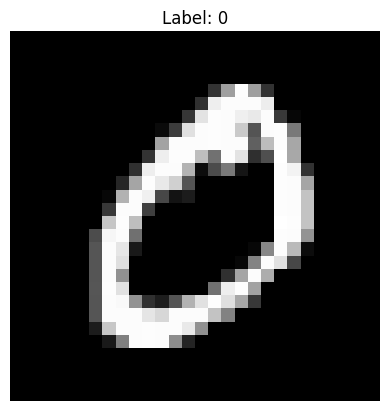

In [4]:
# 이미지와 정답 확인하기
import matplotlib.pyplot as plt

index = 1

plt.imshow(x_train[index].reshape(28,28), cmap = "gray")
plt.title(f"Label: {y_train[index]}")
plt.axis("off") # 축 눈금 안보이게 하기
plt.show()

In [15]:
import time
class MLP:

  def __init__(self,lr,x_train,y_train,x_test,y_test,batch):
    self.lr = lr
    self.x_train = x_train
    self.y_train  =y_train
    self.x_test  = x_test
    self.y_test = y_test
    # input (input, batch)
    # w*x+b 형태

    self.B_x = np.zeros((784,100))
    self.B_y = np.zeros((10,100))
    self.B = batch
    # 가중치
    self.w1 = np.random.normal(0,np.sqrt(2/(784+512)),size =(512,784)) # xaiver (output,input)
    self.w2 = np.random.normal(0,np.sqrt(2/512),size = (128,512))# he
    self.w3 = np.random.normal(0,np.sqrt(2/((128+10))),size =(10,128))# xaiver
    self.b1 = np.zeros((512,1))
    self.b2 = np.zeros((128,1))
    self.b3 = np.zeros((10,1))

    self.z1 = np.zeros((512,self.B))
    self.a1 = np.zeros((512,self.B))
    self.z2 = np.zeros((128,self.B))
    self.a2 = np.zeros((128,self.B))
    self.z3 = np.zeros((10,self.B))
    self.predict = np.zeros((10,self.B))



  def sigmoid(self,x):
    return 1/(1+np.exp(-x))
  def Desigmoid(self,o): # output기준
    return o*(1-o)
  def Relu(self,o):
    return np.maximum(0,o)
  def DeRelu(self,x):  # 입력값 기준
   return (x>0).astype('float64')
  def softmax(self,x):
    c = np.max(x,axis = 0,keepdims =True)
    exp_x = np.exp(x-c)

    return exp_x/np.sum(exp_x, axis = 0, keepdims = True) # 열벡터 (10,batch) -> (1,batch)

  def mean(self,x): # x: (output,B)
    B = x.shape[1]
    tmp = np.sum(x,axis = 1,keepdims = True)/B # (output,1)
    return tmp



  def CN(self,p):
    B = len(self.B_y[0])
    total = -np.sum(self.B_y*np.log(p),axis = 0,keepdims = True)
    avg = np.sum(total)/B

    return avg
  def outputdelta(self,o): #(10,B)
    return o-self.B_y



  def forward(self): # (784,B)
    self.z1 = self.w1 @ self.B_x + self.b1 # (256,B)
    self.a1 = self.sigmoid(self.z1) # (256,B)
    self.z2 = self.w2 @ self.a1 + self.b2 # (128,B)
    self.a2 = self.Relu(self.z2) # (128,B)
    self.z3 = self.w3 @ self.a2 + self.b3 # (10,B)
    self.predict = self.softmax(self.z3) # (10,B)
  # (10,B)
    return self.predict

  def Loss(self): # (10,B)
    result = self.CN(self.predict) # (1,1)
    return result
  def back(self):
    outputdelta = self.outputdelta(self.predict) # (10,B) (B,128)
    self.b3 -= self.lr * self.mean(outputdelta) # (10,1)

    hiddenoutputdelta2 = (self.w3.T @ outputdelta) * self.DeRelu(self.a2)
    self.w3 -= self.lr * (outputdelta @ self.a2.T)/self.B
          #(128,B)

    self.b2 -= self.lr * self.mean(hiddenoutputdelta2) # (128,1)
    hiddenoutputdelta1 = (self.w2.T @ hiddenoutputdelta2) * self.Desigmoid(self.a1) # (256,B)
    self.w2 -= self.lr * (hiddenoutputdelta2 @ self.a1.T)/self.B # (128,256)

    self.b1 -= self.lr * self.mean(hiddenoutputdelta1) # (256,1)
    self.w1 -= self.lr * (hiddenoutputdelta1 @ self.B_x.T)/self.B # (256,784)

  def training(self):

    for epoch in range(100):

      total_loss = 0.0
      batch_count = 0

      for batch in range(0,len(self.x_train),self.B):
        self.B_x = self.x_train[batch:batch+self.B].T # 0~99, 100~199
        self.B_y = self.y_train[batch:batch+self.B].T

        start = time.perf_counter()

        output = self.forward()
        forward_time = time.perf_counter() - start
        start = time.perf_counter()
        loss = self.Loss()
        loss_time = time.perf_counter() - start

        start = time.perf_counter()

        self.back()
        total_loss += loss
        batch_count += 1
        back_time = time.perf_counter() - start

        if batch == 0:
                print(f"Forward: {forward_time:.6f}초")
                print(f"Loss:    {loss_time:.6f}초")
                print(f"Back:    {back_time:.6f}초")
      print(f"epoch: {epoch}, loss: {total_loss / batch_count}")

  def evaluate(self):
    count = 0
    for i in range(0,10000,100):
      self.B_x = self.x_test[i:i+100].T
      self.B_y = self.y_test[i:i+100].T
      self.forward()
      ans = np.argmax(self.predict, axis=0)
      target = np.argmax(self.B_y, axis=0)
      for j in range(100):

        if ans[j] == target[j]:

           count +=1
        else:

          print("B_x shape:", self.B_x.shape)
          print("j:", j)
          print(f"predict: {ans[j]}")
          img = self.B_x.T[j].reshape(28, 28)

          plt.imshow(img, cmap="gray")
          plt.title(f"Label: {np.argmax(self.B_y.T[j])}")
          plt.axis("off")
          plt.show()
    print(f"accuracy:  {(count/10000)*100}")















Forward: 0.034758초
Loss:    0.000081초
Back:    0.024112초
epoch: 0, loss: 0.6054681175352475
Forward: 0.005731초
Loss:    0.000076초
Back:    0.007033초
epoch: 1, loss: 0.29245168432143187
Forward: 0.005579초
Loss:    0.000076초
Back:    0.006837초
epoch: 2, loss: 0.2349774857311275
Forward: 0.007437초
Loss:    0.000073초
Back:    0.015420초
epoch: 3, loss: 0.2041609315294386
Forward: 0.005637초
Loss:    0.000075초
Back:    0.006801초
epoch: 4, loss: 0.1786352881028185
Forward: 0.005237초
Loss:    0.000070초
Back:    0.006475초
epoch: 5, loss: 0.16341776818791964
Forward: 0.031245초
Loss:    0.000078초
Back:    0.025569초
epoch: 6, loss: 0.14640767143919756
Forward: 0.005437초
Loss:    0.000073초
Back:    0.006782초
epoch: 7, loss: 0.13584404018287713
Forward: 0.005079초
Loss:    0.000071초
Back:    0.006517초
epoch: 8, loss: 0.12444949483962274
Forward: 0.012194초
Loss:    0.000077초
Back:    0.015104초
epoch: 9, loss: 0.11433775162059999
Forward: 0.005911초
Loss:    0.000075초
Back:    0.006925초
epoch: 10, loss: 

/tmp/ipykernel_6948/866489768.py:34: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-x))


epoch: 12, loss: 0.09174881517321591
Forward: 0.005176초
Loss:    0.000071초
Back:    0.011031초
epoch: 13, loss: 0.08727233205812206
Forward: 0.005523초
Loss:    0.000076초
Back:    0.007540초
epoch: 14, loss: 0.08280307149197925
Forward: 0.006803초
Loss:    0.000094초
Back:    0.009701초
epoch: 15, loss: 0.07985698302558612
Forward: 0.005893초
Loss:    0.000074초
Back:    0.010294초
epoch: 16, loss: 0.07509478217518081
Forward: 0.005599초
Loss:    0.000117초
Back:    0.007737초
epoch: 17, loss: 0.06809789109136725
Forward: 0.006597초
Loss:    0.000075초
Back:    0.007718초
epoch: 18, loss: 0.06355836379049064
Forward: 0.032907초
Loss:    0.000081초
Back:    0.027703초
epoch: 19, loss: 0.06054718830468107
Forward: 0.005648초
Loss:    0.000074초
Back:    0.007053초
epoch: 20, loss: 0.05639992689224678
Forward: 0.005609초
Loss:    0.000074초
Back:    0.006940초
epoch: 21, loss: 0.0551877570729314
Forward: 0.005452초
Loss:    0.000073초
Back:    0.006661초
epoch: 22, loss: 0.05251250235189556
Forward: 0.005730초
Loss:

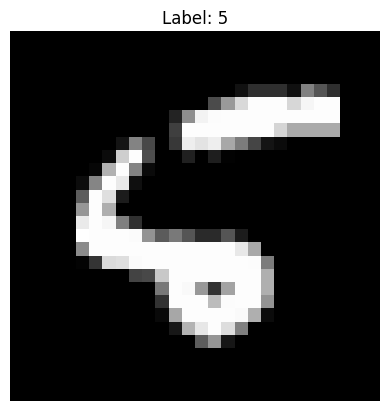

B_x shape: (784, 100)
j: 24
predict: 4


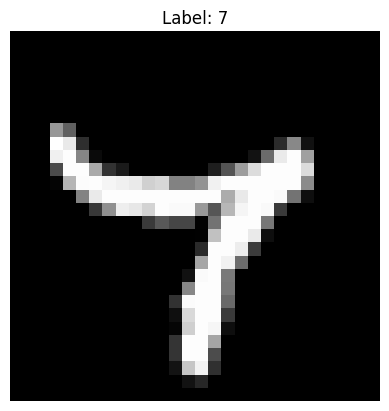

B_x shape: (784, 100)
j: 49
predict: 8


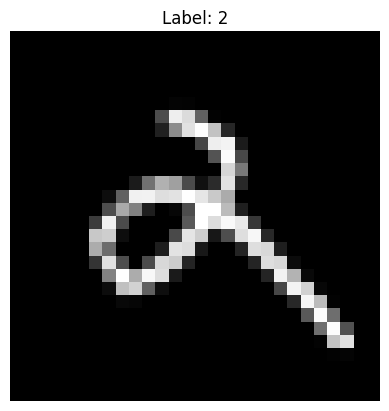

B_x shape: (784, 100)
j: 17
predict: 5


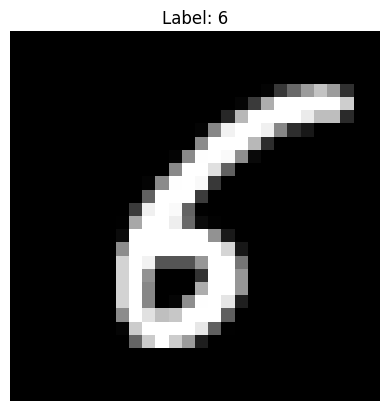

B_x shape: (784, 100)
j: 41
predict: 8


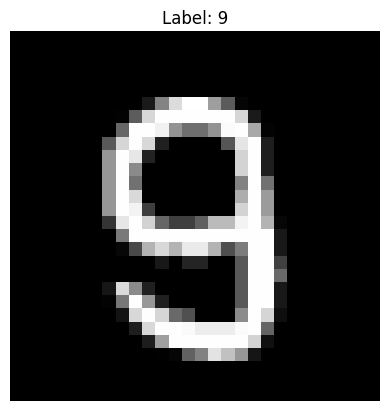

B_x shape: (784, 100)
j: 47
predict: 2


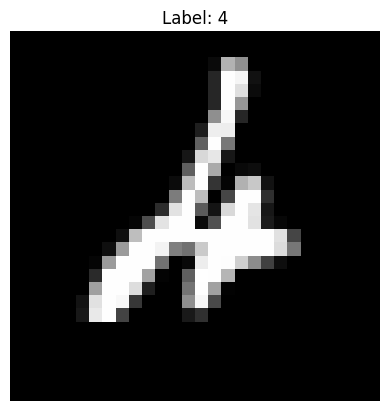

B_x shape: (784, 100)
j: 59
predict: 0


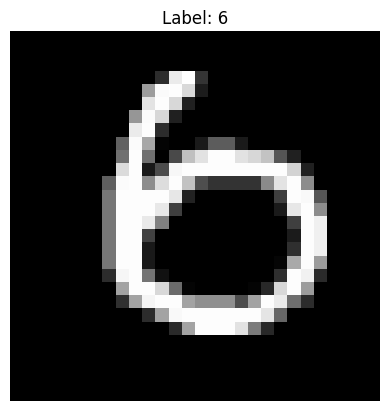

B_x shape: (784, 100)
j: 21
predict: 7


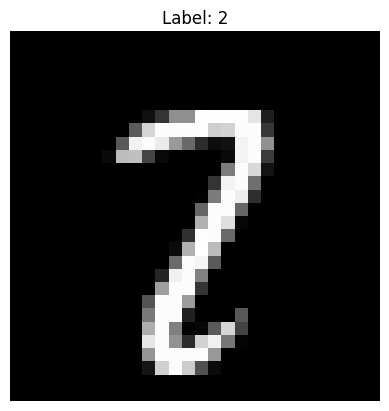

B_x shape: (784, 100)
j: 81
predict: 7


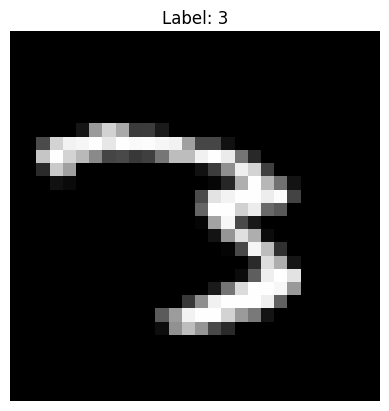

B_x shape: (784, 100)
j: 45
predict: 0


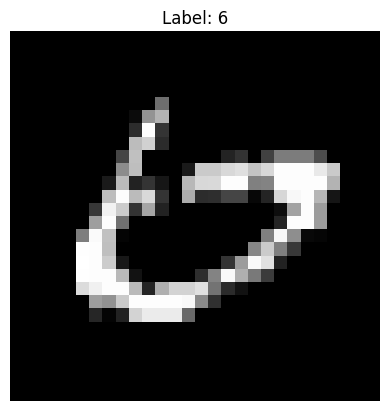

B_x shape: (784, 100)
j: 48
predict: 8


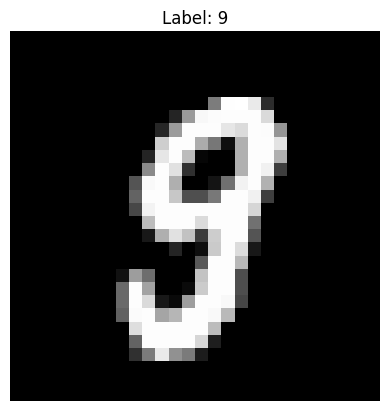

B_x shape: (784, 100)
j: 95
predict: 0


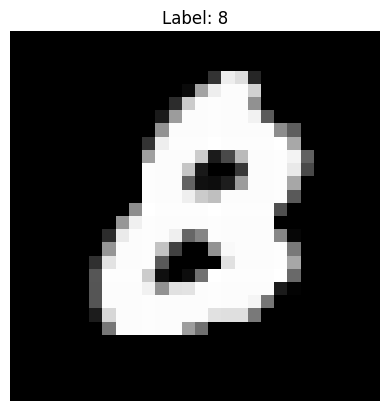

B_x shape: (784, 100)
j: 43
predict: 3


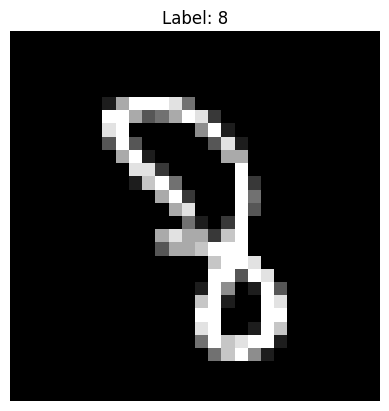

B_x shape: (784, 100)
j: 51
predict: 3


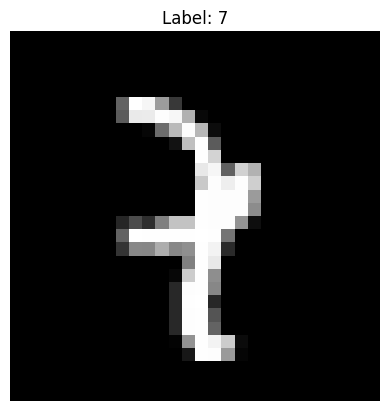

B_x shape: (784, 100)
j: 78
predict: 2


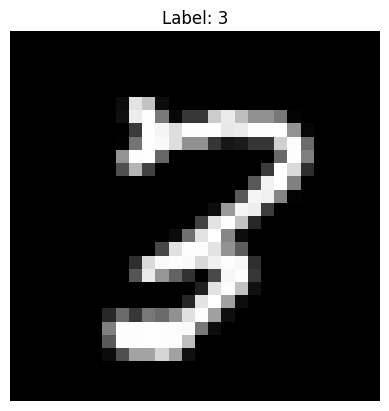

B_x shape: (784, 100)
j: 82
predict: 2


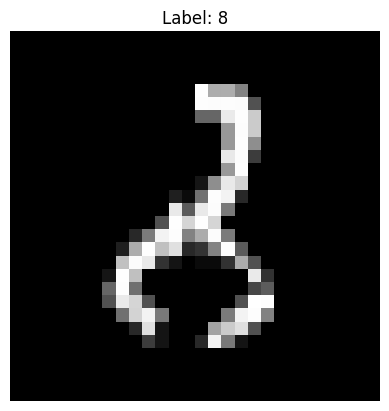

B_x shape: (784, 100)
j: 91
predict: 3


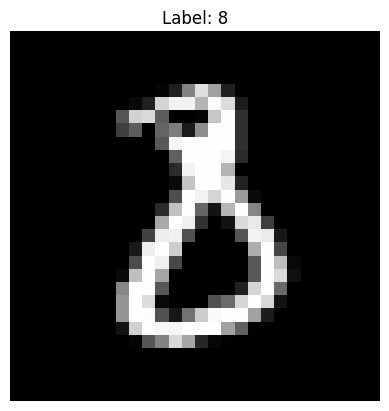

B_x shape: (784, 100)
j: 19
predict: 8


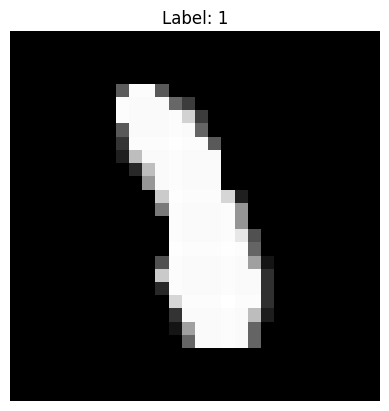

B_x shape: (784, 100)
j: 84
predict: 1


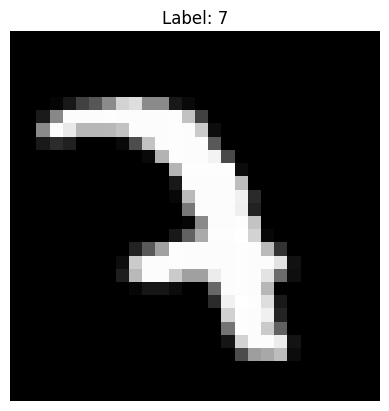

B_x shape: (784, 100)
j: 91
predict: 4


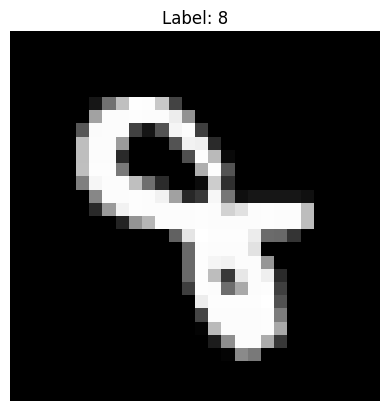

B_x shape: (784, 100)
j: 7
predict: 9


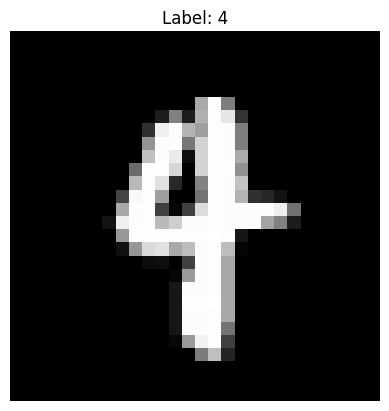

B_x shape: (784, 100)
j: 20
predict: 8


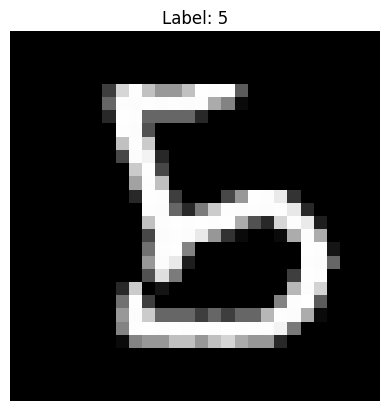

B_x shape: (784, 100)
j: 40
predict: 9


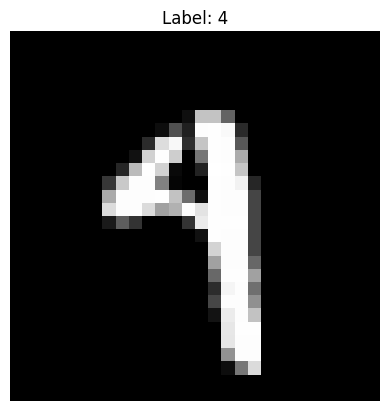

B_x shape: (784, 100)
j: 71
predict: 9


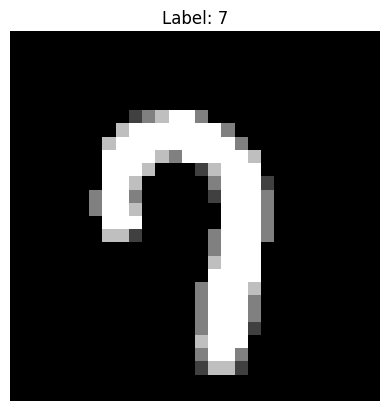

B_x shape: (784, 100)
j: 38
predict: 5


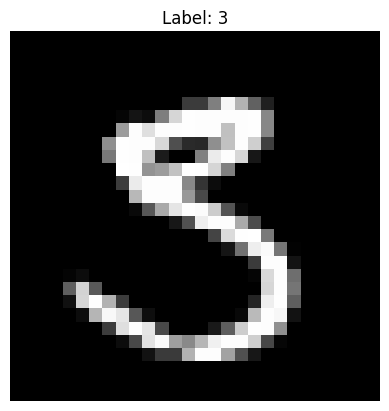

B_x shape: (784, 100)
j: 39
predict: 0


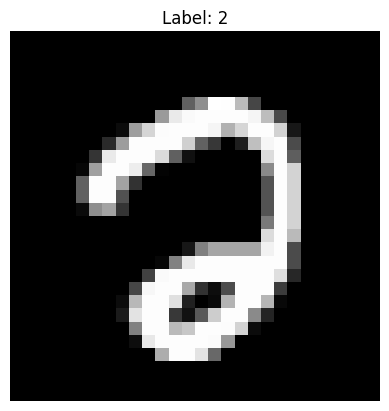

B_x shape: (784, 100)
j: 47
predict: 9


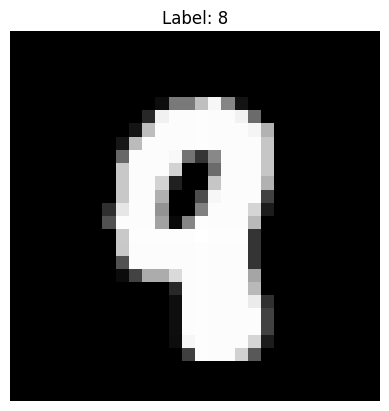

B_x shape: (784, 100)
j: 51
predict: 4


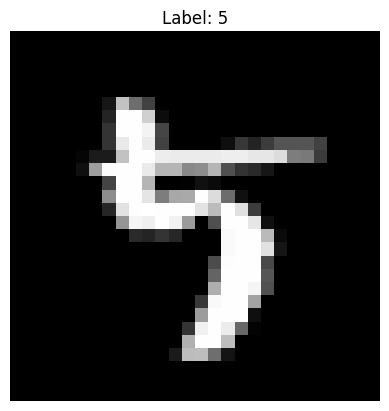

B_x shape: (784, 100)
j: 56
predict: 2


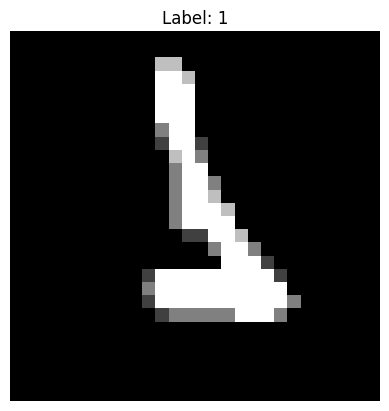

B_x shape: (784, 100)
j: 65
predict: 0


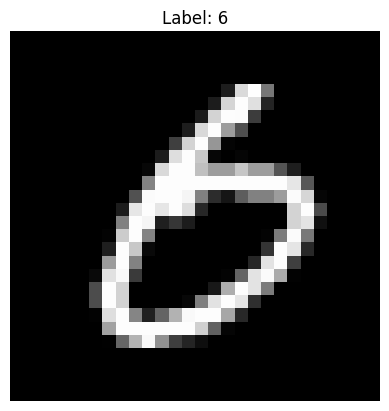

B_x shape: (784, 100)
j: 14
predict: 5


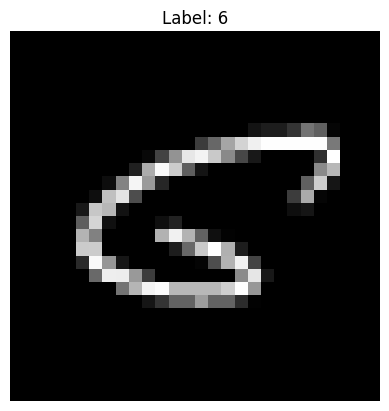

B_x shape: (784, 100)
j: 32
predict: 8


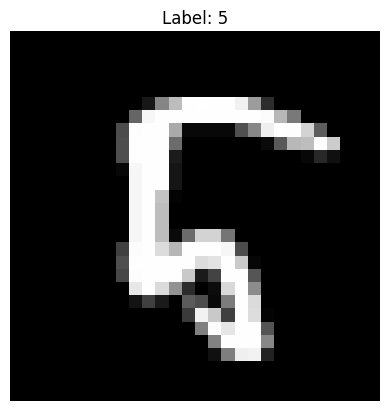

B_x shape: (784, 100)
j: 39
predict: 1


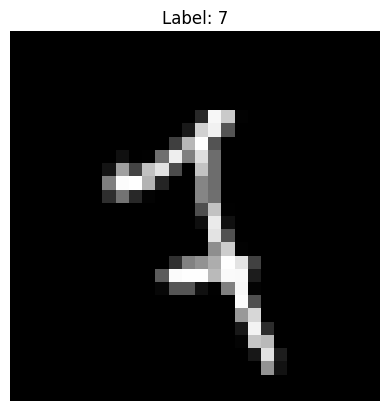

B_x shape: (784, 100)
j: 62
predict: 7


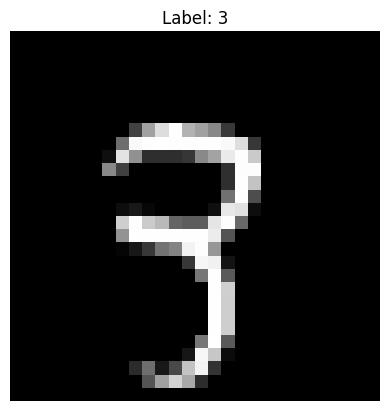

B_x shape: (784, 100)
j: 12
predict: 6


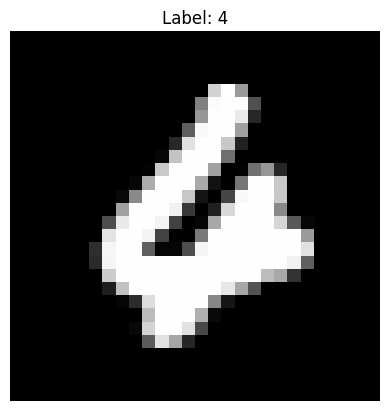

B_x shape: (784, 100)
j: 28
predict: 7


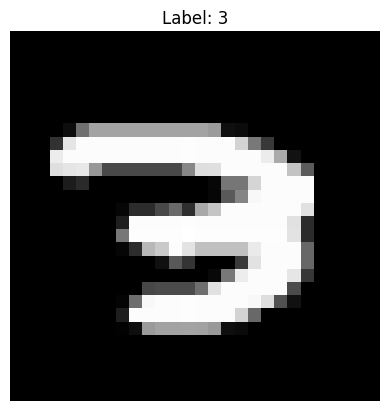

B_x shape: (784, 100)
j: 53
predict: 5


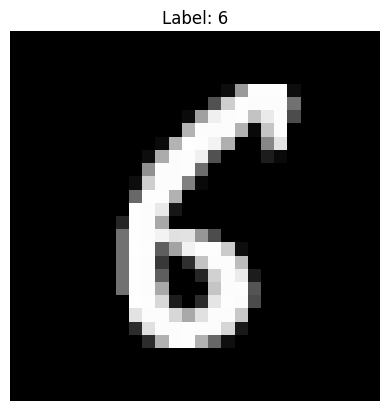

B_x shape: (784, 100)
j: 81
predict: 1


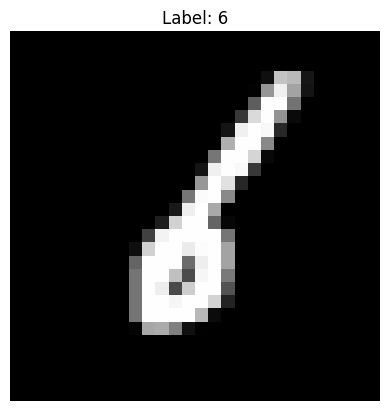

B_x shape: (784, 100)
j: 82
predict: 8


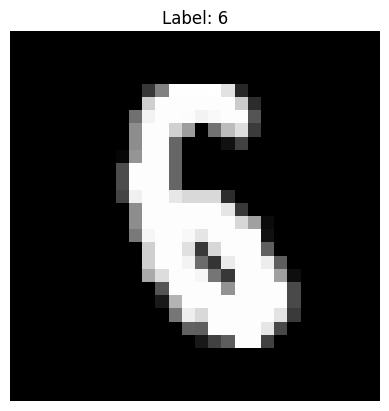

B_x shape: (784, 100)
j: 92
predict: 4


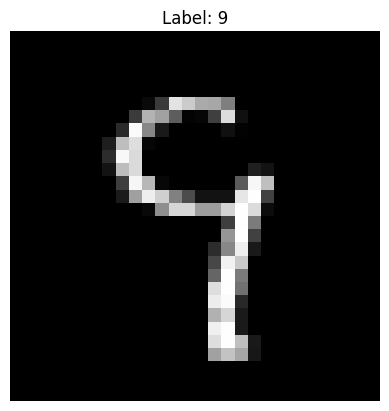

B_x shape: (784, 100)
j: 94
predict: 9


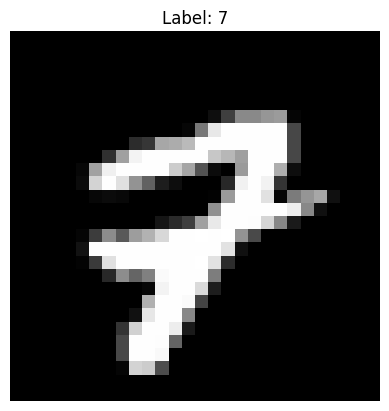

B_x shape: (784, 100)
j: 26
predict: 2


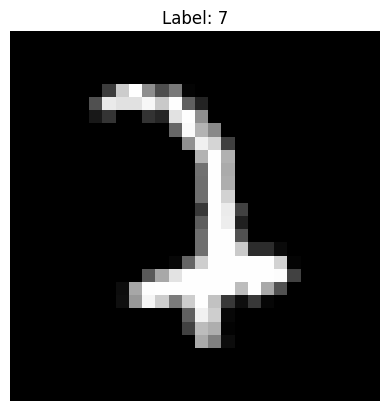

B_x shape: (784, 100)
j: 32
predict: 4


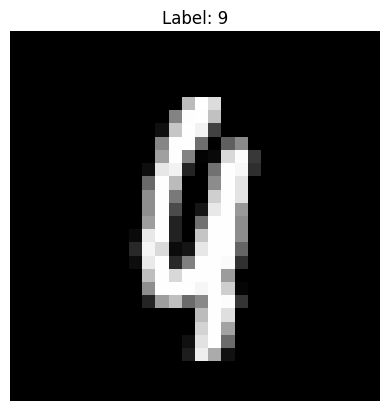

B_x shape: (784, 100)
j: 42
predict: 9


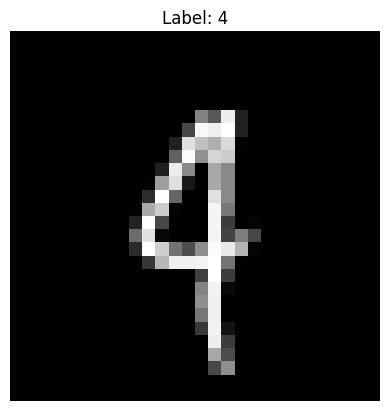

B_x shape: (784, 100)
j: 47
predict: 3


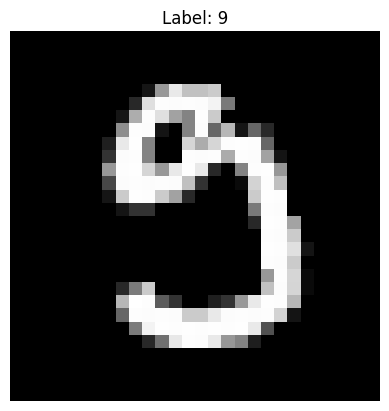

B_x shape: (784, 100)
j: 60
predict: 1


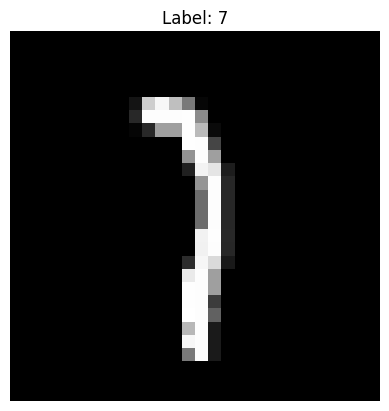

B_x shape: (784, 100)
j: 83
predict: 2


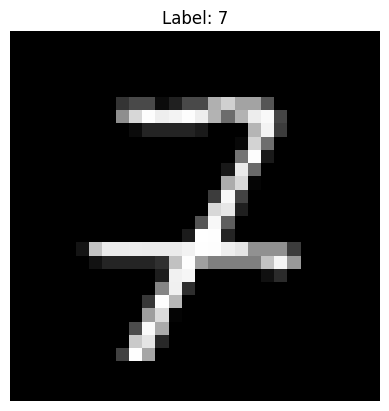

B_x shape: (784, 100)
j: 89
predict: 9


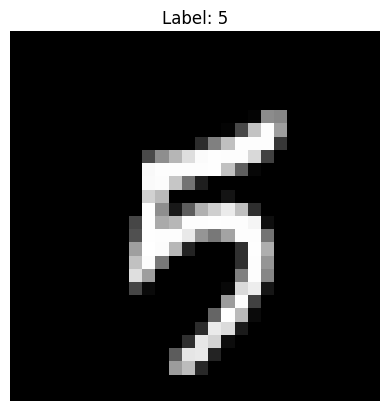

B_x shape: (784, 100)
j: 99
predict: 7


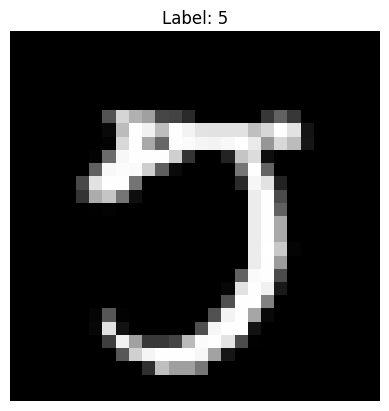

B_x shape: (784, 100)
j: 19
predict: 3


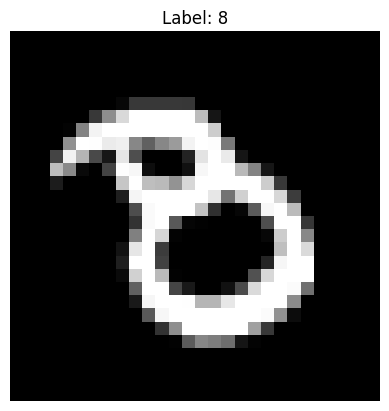

B_x shape: (784, 100)
j: 26
predict: 1


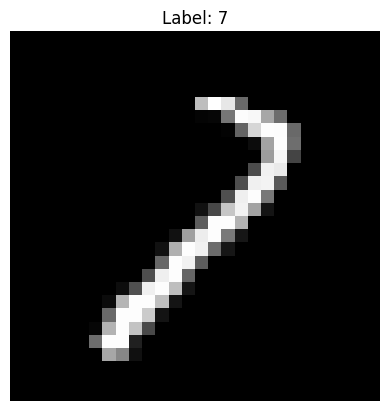

B_x shape: (784, 100)
j: 14
predict: 7


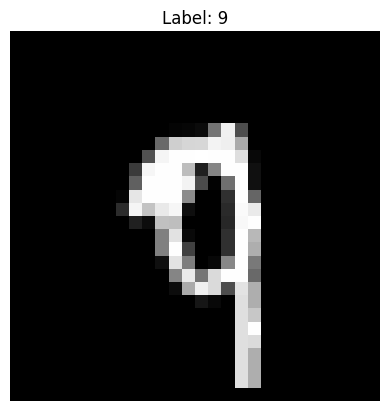

B_x shape: (784, 100)
j: 29
predict: 4


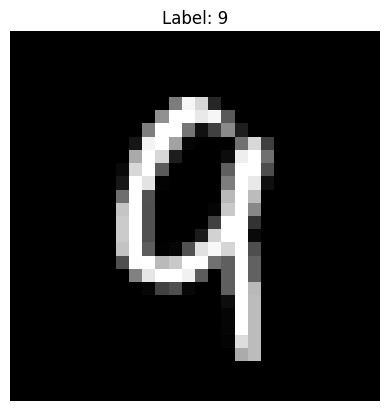

B_x shape: (784, 100)
j: 44
predict: 4


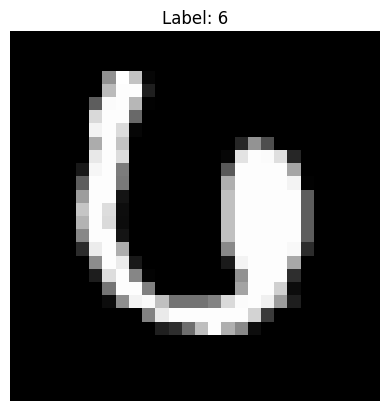

B_x shape: (784, 100)
j: 0
predict: 1


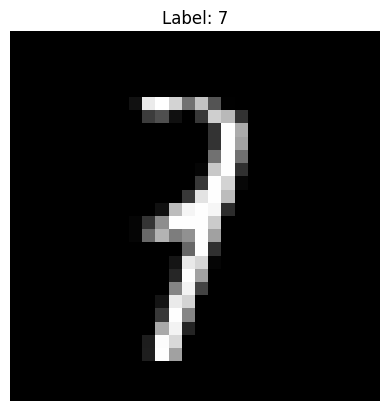

B_x shape: (784, 100)
j: 22
predict: 9


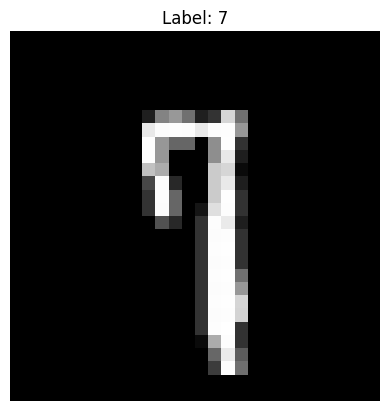

B_x shape: (784, 100)
j: 25
predict: 0


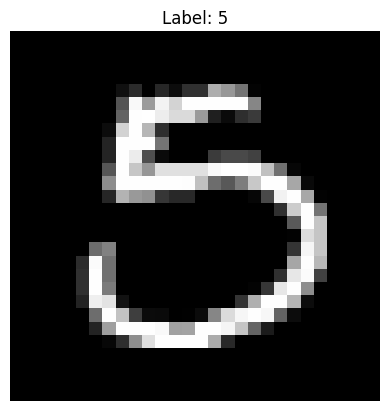

B_x shape: (784, 100)
j: 27
predict: 6


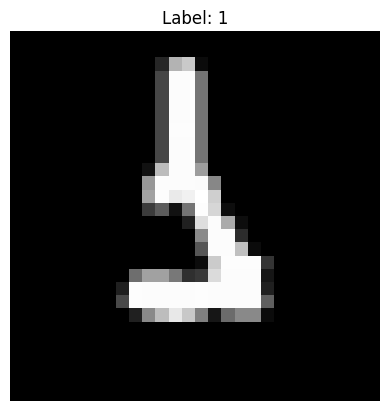

B_x shape: (784, 100)
j: 30
predict: 3


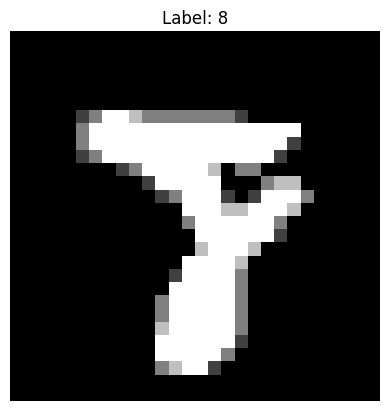

B_x shape: (784, 100)
j: 49
predict: 2


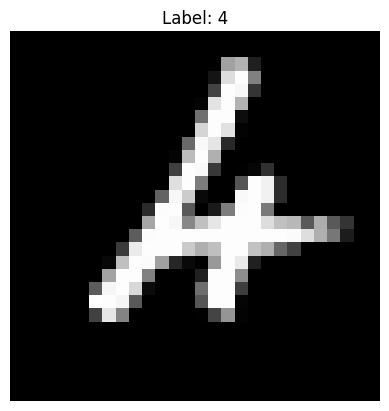

B_x shape: (784, 100)
j: 81
predict: 9


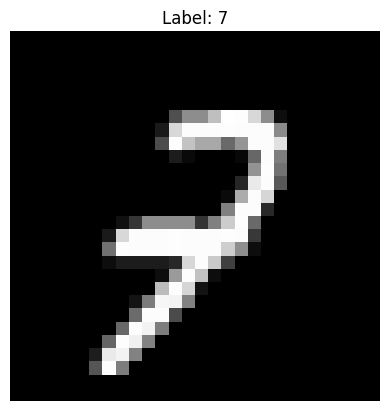

B_x shape: (784, 100)
j: 9
predict: 6


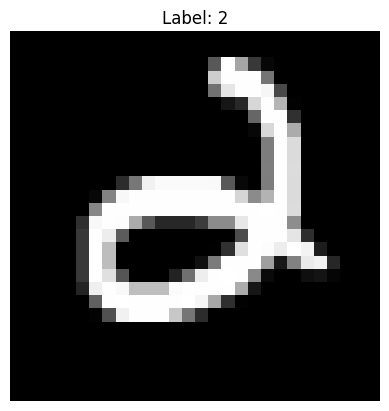

B_x shape: (784, 100)
j: 81
predict: 7


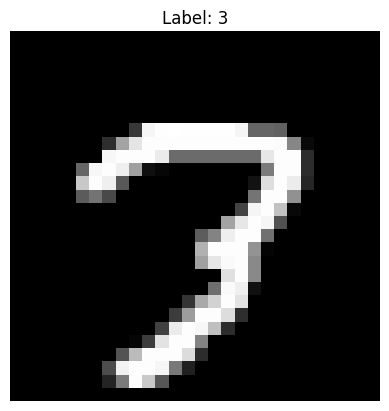

B_x shape: (784, 100)
j: 9
predict: 5


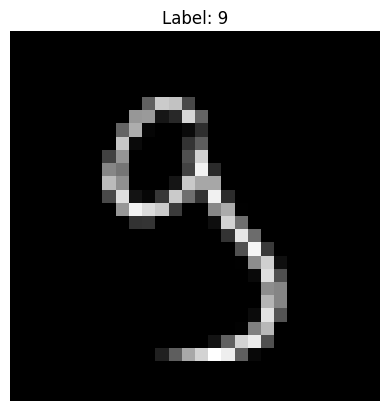

B_x shape: (784, 100)
j: 17
predict: 0


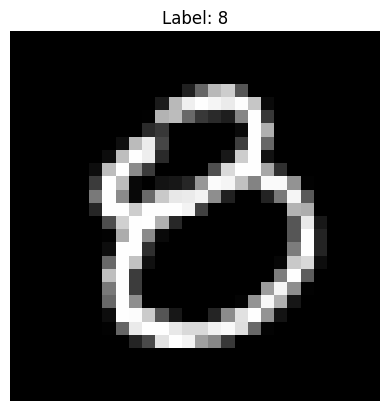

B_x shape: (784, 100)
j: 37
predict: 1


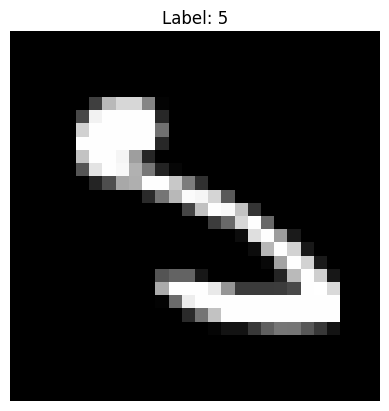

B_x shape: (784, 100)
j: 51
predict: 2


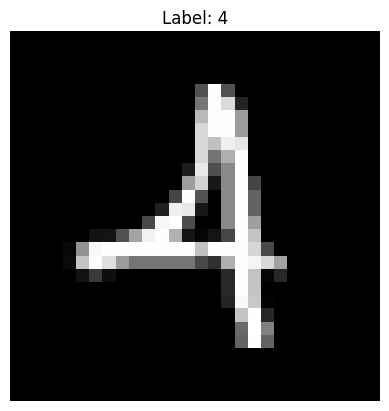

B_x shape: (784, 100)
j: 54
predict: 2


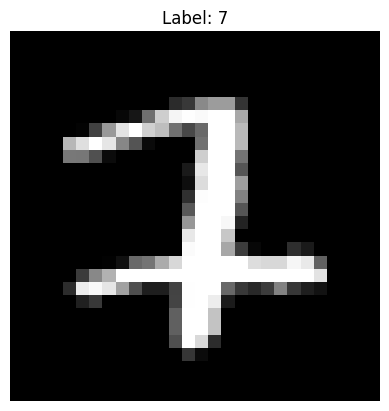

B_x shape: (784, 100)
j: 90
predict: 8


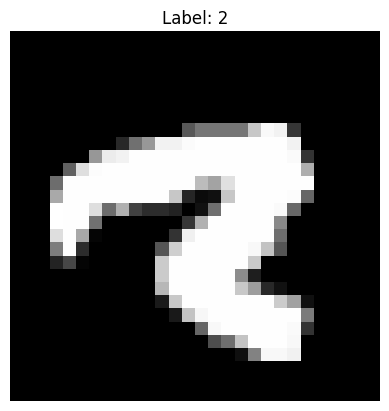

B_x shape: (784, 100)
j: 28
predict: 7


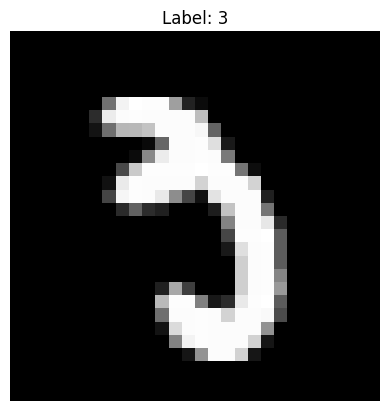

B_x shape: (784, 100)
j: 1
predict: 4


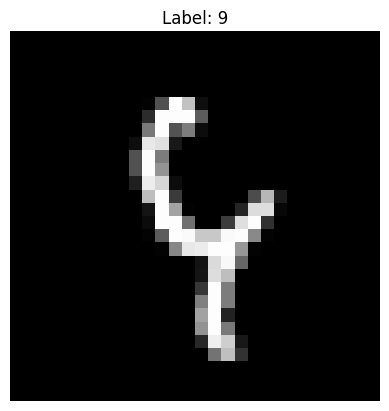

B_x shape: (784, 100)
j: 11
predict: 6


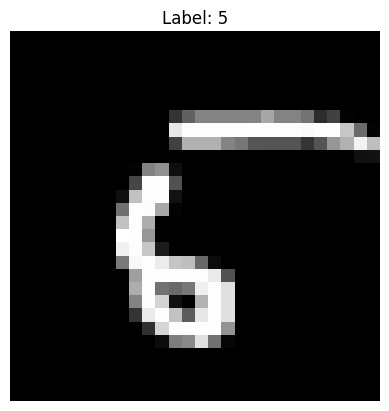

B_x shape: (784, 100)
j: 41
predict: 8


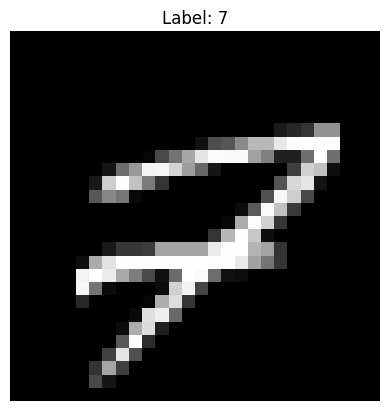

B_x shape: (784, 100)
j: 52
predict: 8


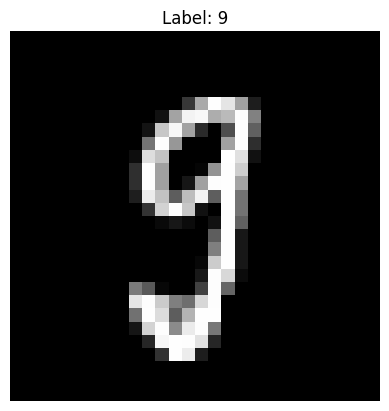

B_x shape: (784, 100)
j: 55
predict: 2


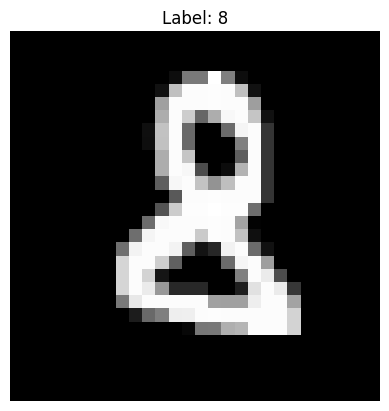

B_x shape: (784, 100)
j: 82
predict: 5


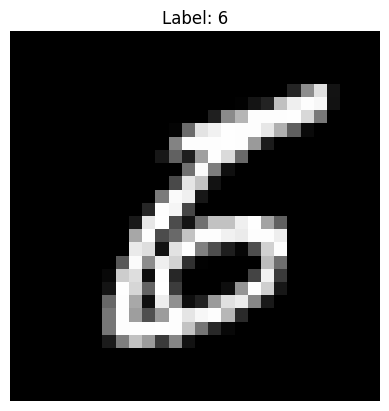

B_x shape: (784, 100)
j: 16
predict: 2


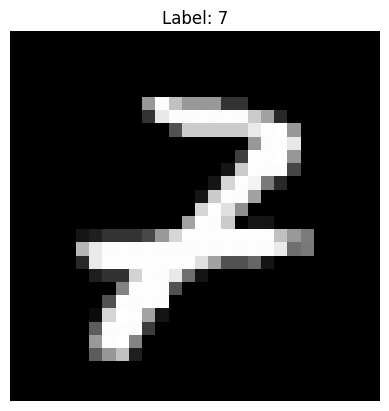

B_x shape: (784, 100)
j: 35
predict: 3


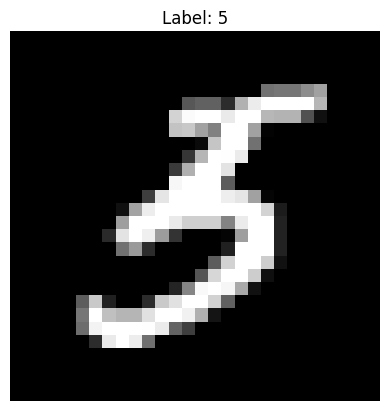

B_x shape: (784, 100)
j: 44
predict: 7


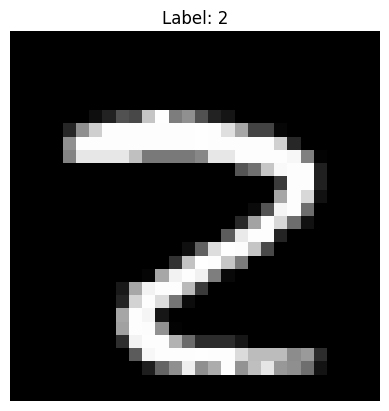

B_x shape: (784, 100)
j: 53
predict: 9


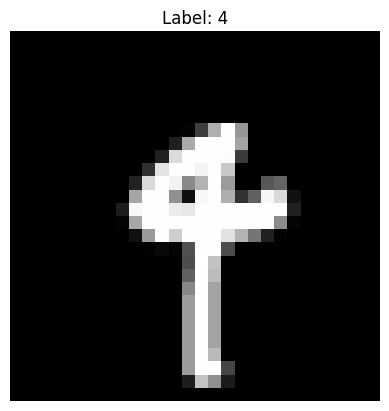

B_x shape: (784, 100)
j: 70
predict: 9


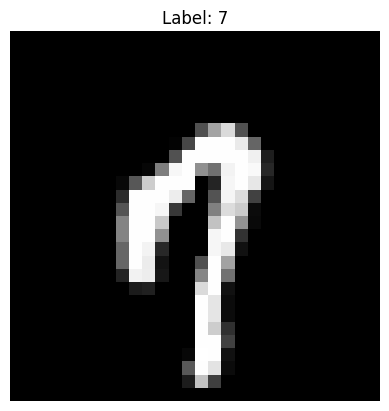

B_x shape: (784, 100)
j: 98
predict: 0


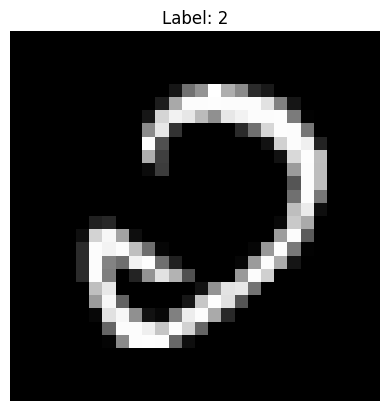

B_x shape: (784, 100)
j: 9
predict: 4


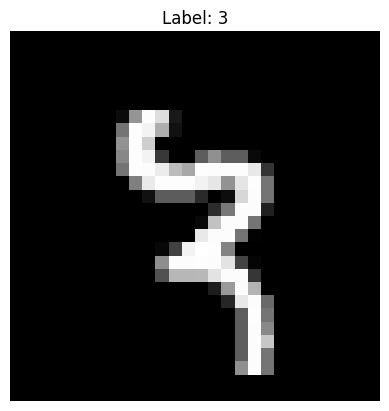

B_x shape: (784, 100)
j: 18
predict: 4


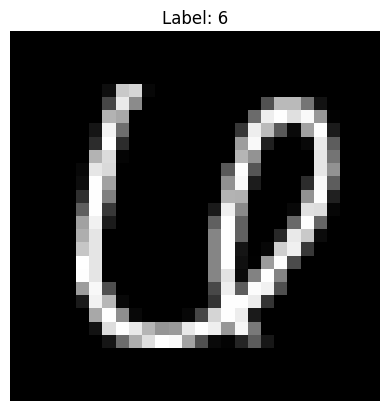

B_x shape: (784, 100)
j: 30
predict: 9


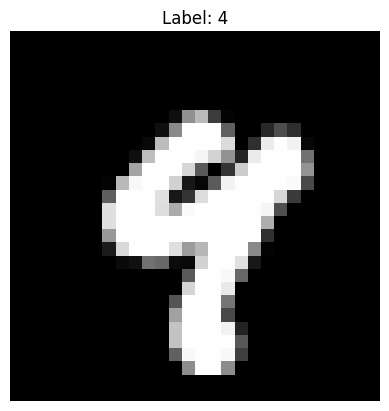

B_x shape: (784, 100)
j: 35
predict: 1


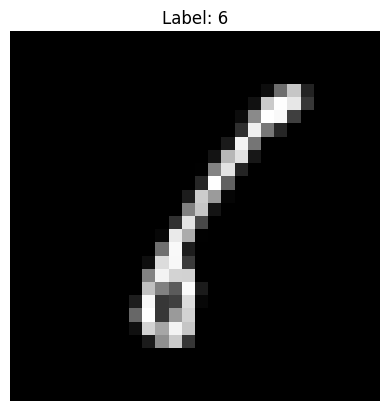

B_x shape: (784, 100)
j: 82
predict: 2


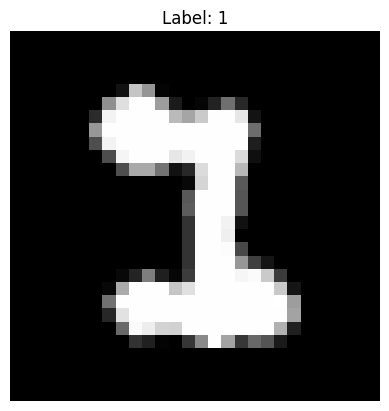

B_x shape: (784, 100)
j: 85
predict: 5


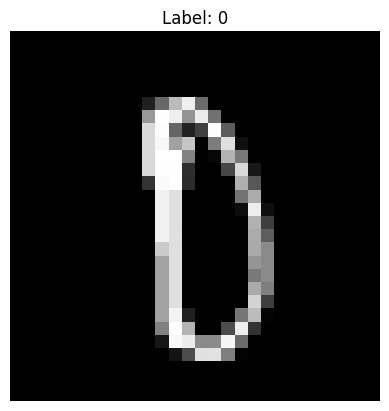

B_x shape: (784, 100)
j: 86
predict: 3


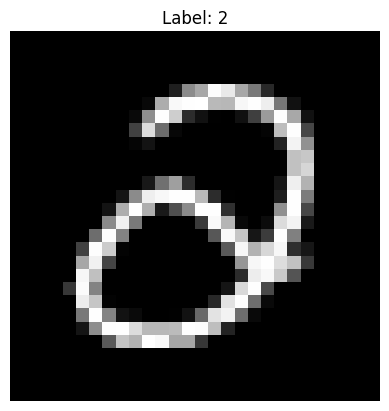

B_x shape: (784, 100)
j: 24
predict: 6


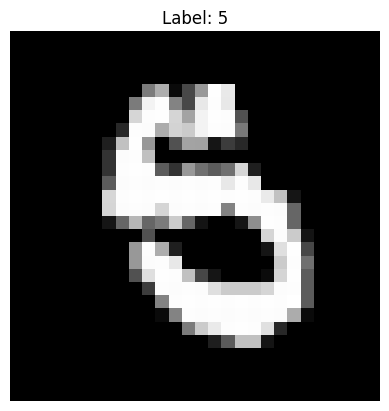

B_x shape: (784, 100)
j: 72
predict: 0


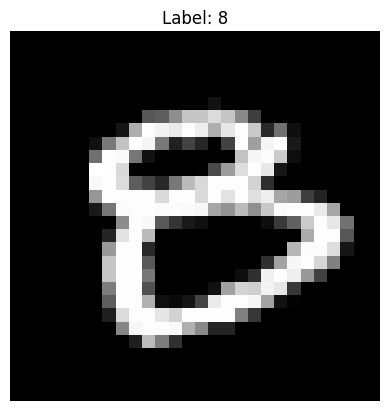

B_x shape: (784, 100)
j: 93
predict: 6


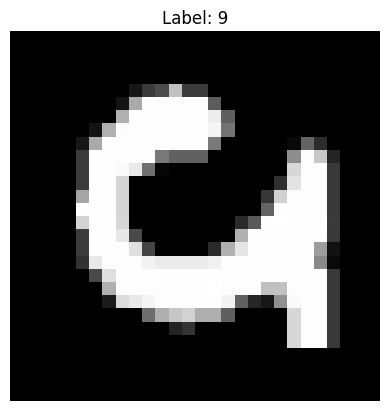

B_x shape: (784, 100)
j: 69
predict: 9


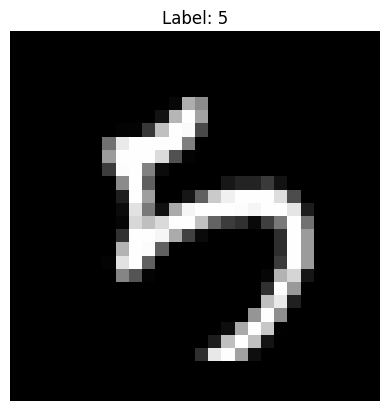

B_x shape: (784, 100)
j: 87
predict: 1


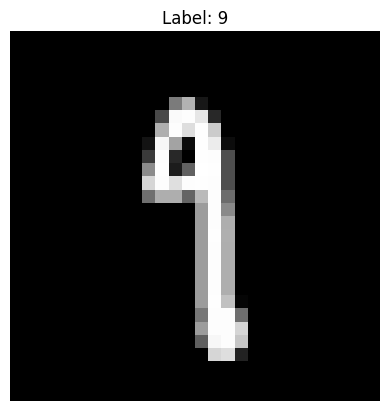

B_x shape: (784, 100)
j: 6
predict: 4


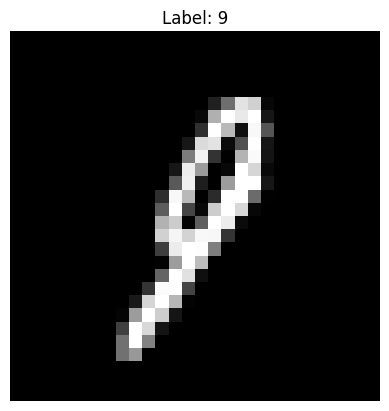

B_x shape: (784, 100)
j: 14
predict: 7


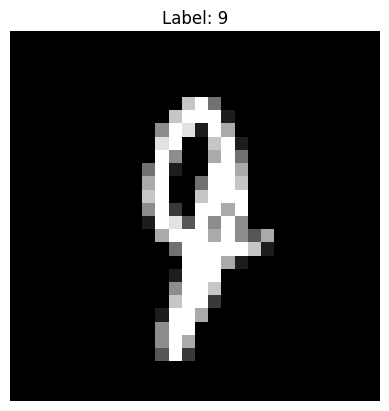

B_x shape: (784, 100)
j: 22
predict: 4


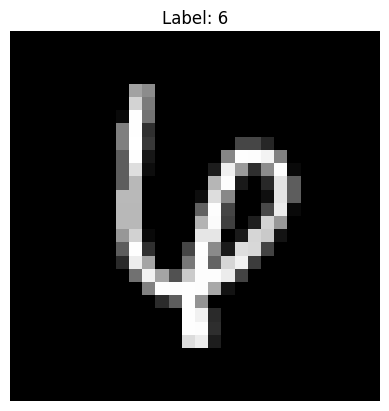

B_x shape: (784, 100)
j: 88
predict: 4


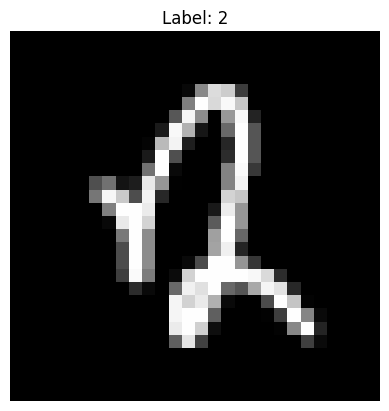

B_x shape: (784, 100)
j: 78
predict: 2


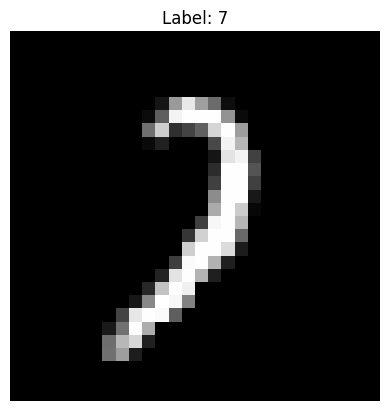

B_x shape: (784, 100)
j: 97
predict: 3


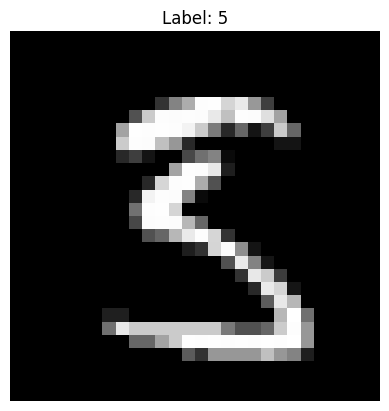

B_x shape: (784, 100)
j: 7
predict: 2


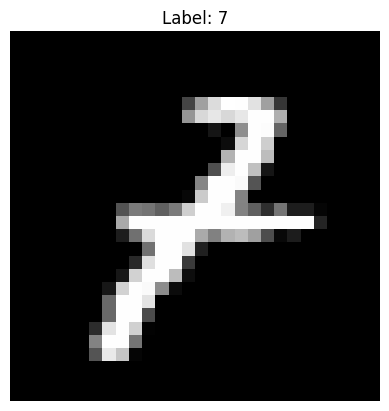

B_x shape: (784, 100)
j: 48
predict: 0


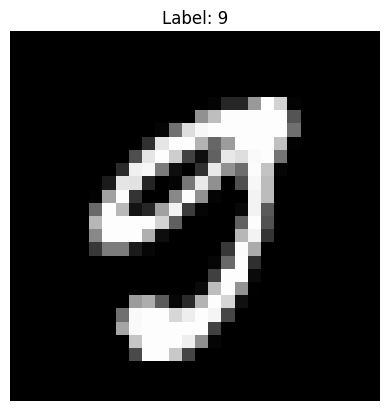

B_x shape: (784, 100)
j: 54
predict: 1


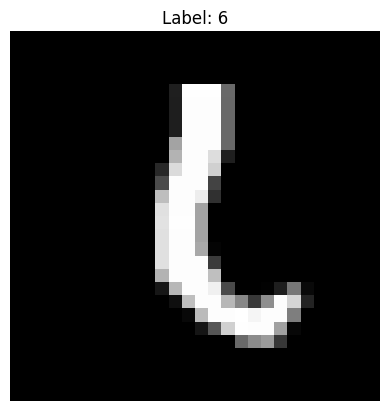

B_x shape: (784, 100)
j: 95
predict: 4


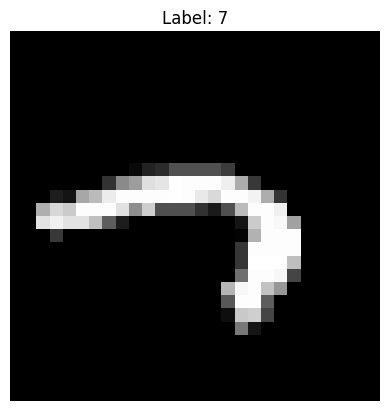

B_x shape: (784, 100)
j: 58
predict: 5


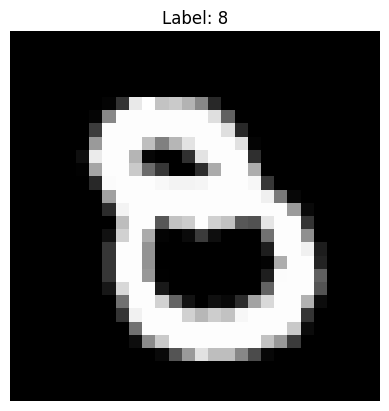

B_x shape: (784, 100)
j: 60
predict: 4


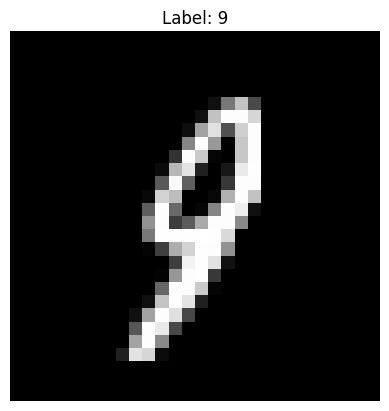

B_x shape: (784, 100)
j: 63
predict: 4


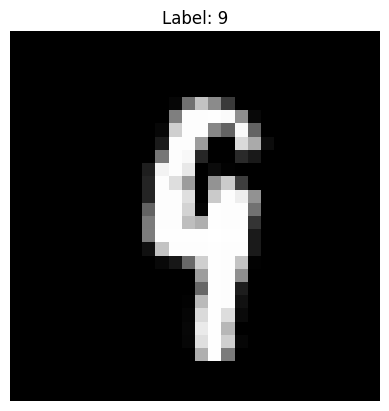

B_x shape: (784, 100)
j: 77
predict: 7


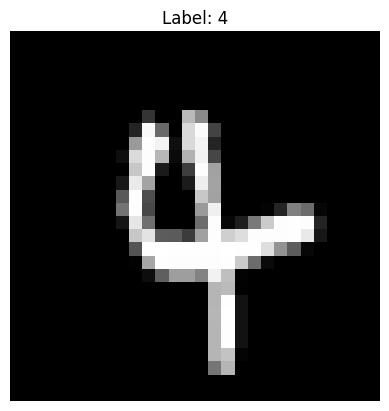

B_x shape: (784, 100)
j: 96
predict: 0


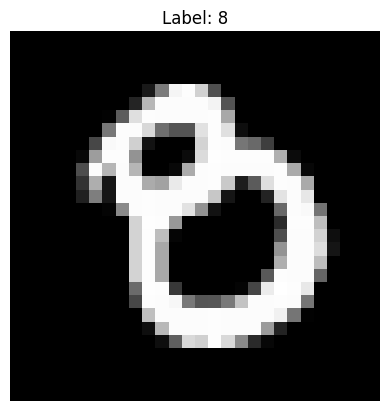

B_x shape: (784, 100)
j: 21
predict: 0


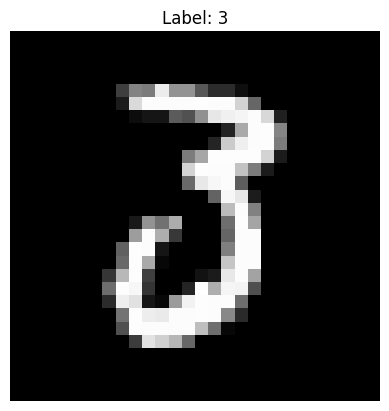

B_x shape: (784, 100)
j: 27
predict: 2


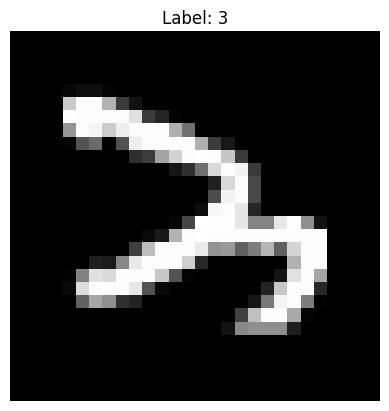

B_x shape: (784, 100)
j: 38
predict: 6


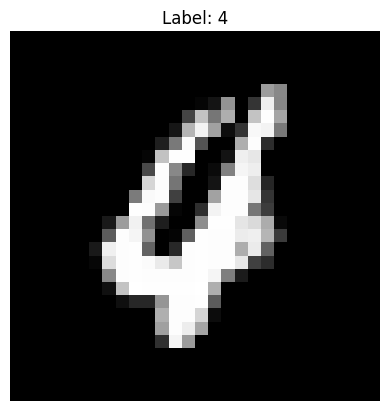

B_x shape: (784, 100)
j: 39
predict: 5


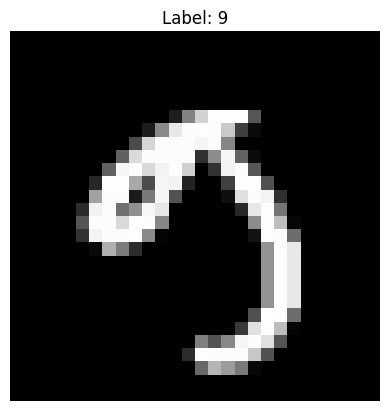

B_x shape: (784, 100)
j: 53
predict: 5


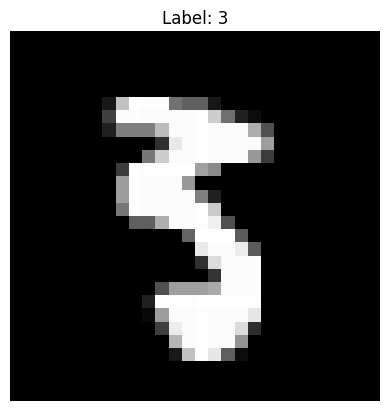

B_x shape: (784, 100)
j: 30
predict: 8


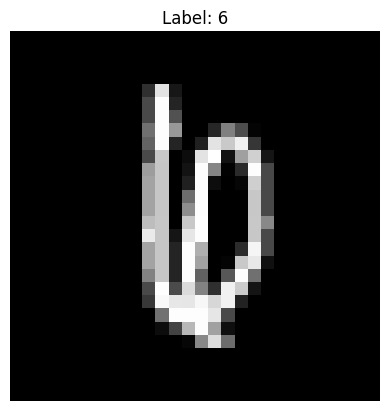

B_x shape: (784, 100)
j: 60
predict: 7


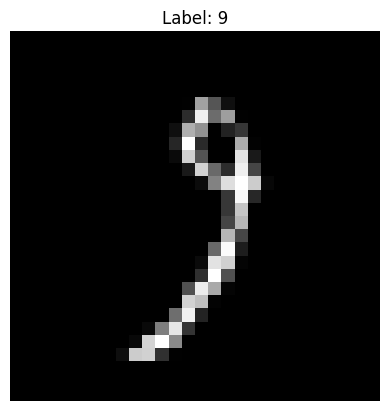

B_x shape: (784, 100)
j: 62
predict: 5


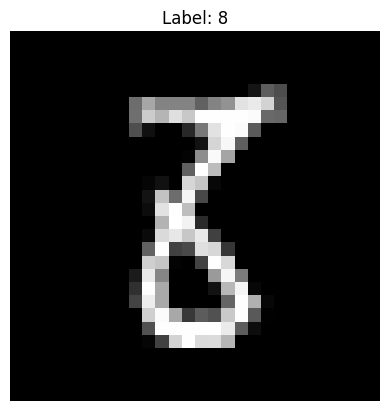

B_x shape: (784, 100)
j: 73
predict: 2


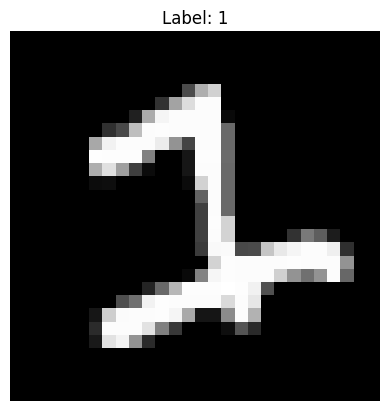

B_x shape: (784, 100)
j: 17
predict: 4


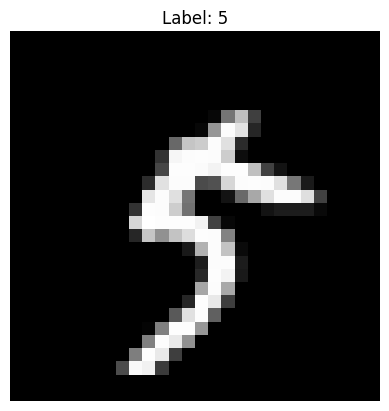

B_x shape: (784, 100)
j: 57
predict: 3


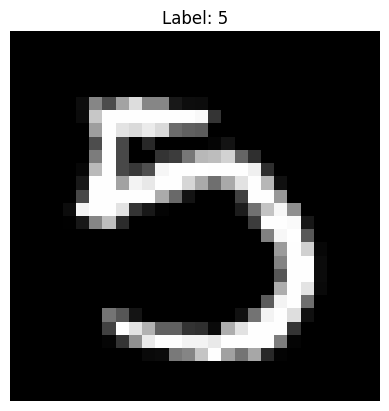

B_x shape: (784, 100)
j: 89
predict: 4


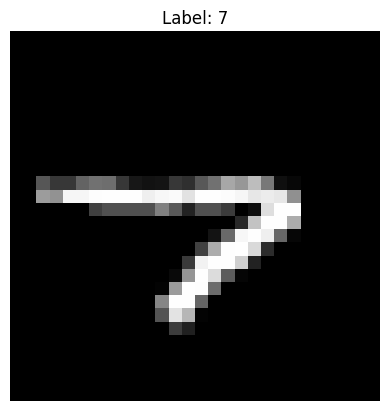

B_x shape: (784, 100)
j: 6
predict: 3


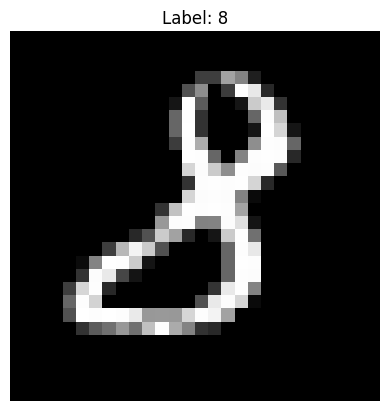

B_x shape: (784, 100)
j: 51
predict: 9


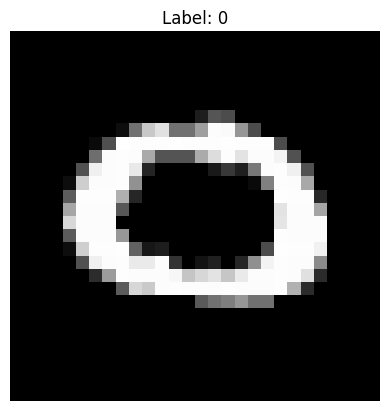

B_x shape: (784, 100)
j: 89
predict: 9


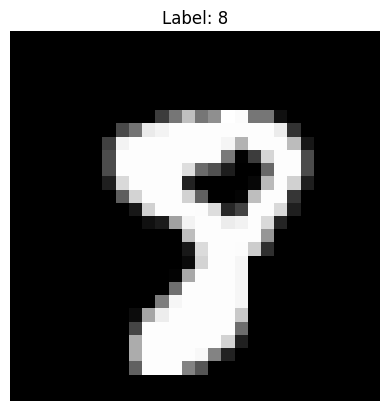

B_x shape: (784, 100)
j: 69
predict: 1


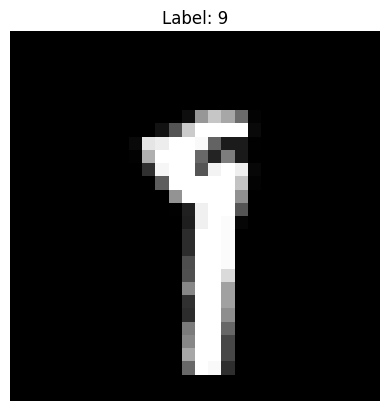

B_x shape: (784, 100)
j: 75
predict: 3


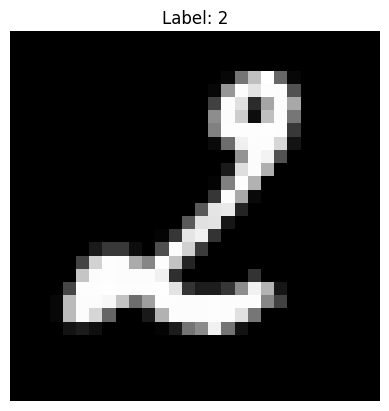

B_x shape: (784, 100)
j: 22
predict: 0


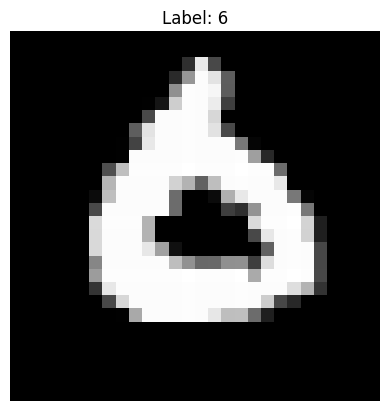

B_x shape: (784, 100)
j: 3
predict: 1


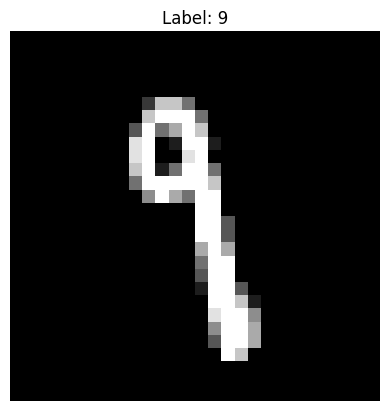

B_x shape: (784, 100)
j: 20
predict: 4


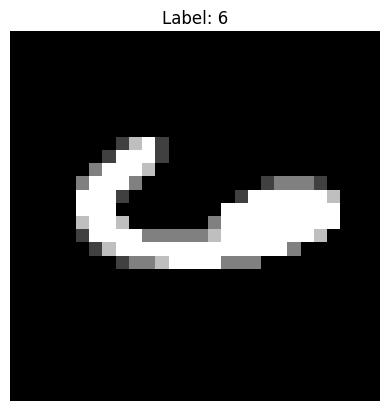

B_x shape: (784, 100)
j: 49
predict: 2


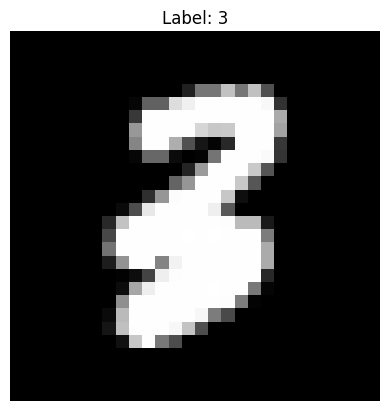

B_x shape: (784, 100)
j: 58
predict: 0


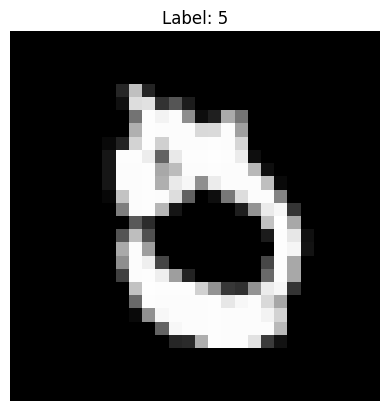

B_x shape: (784, 100)
j: 59
predict: 5


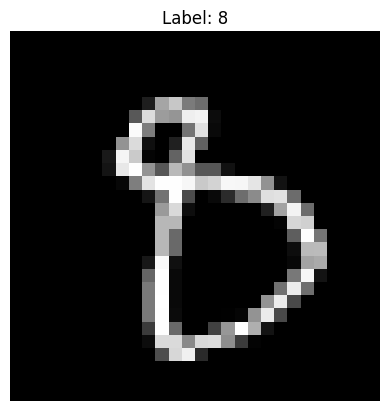

B_x shape: (784, 100)
j: 67
predict: 5


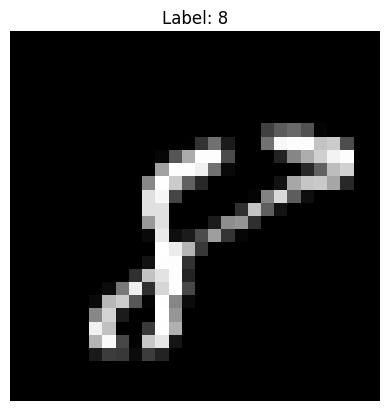

B_x shape: (784, 100)
j: 97
predict: 3


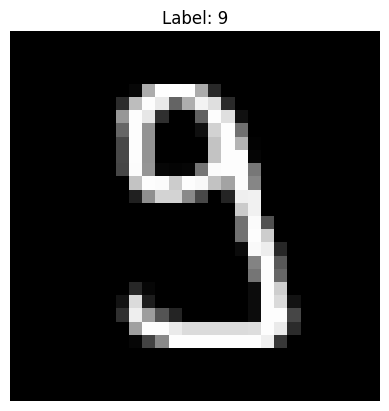

B_x shape: (784, 100)
j: 81
predict: 3


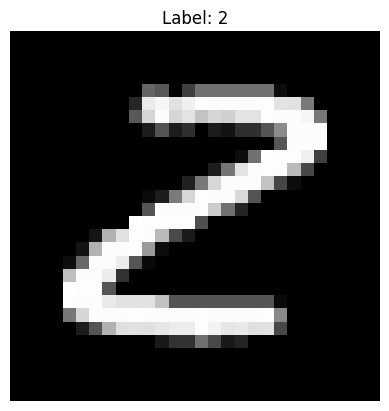

B_x shape: (784, 100)
j: 18
predict: 9


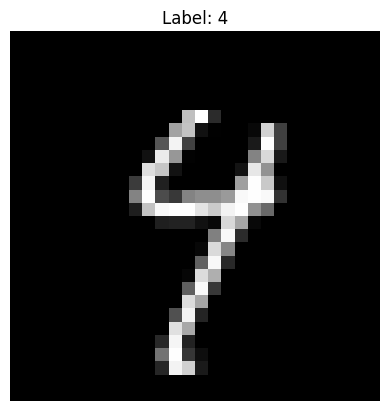

B_x shape: (784, 100)
j: 49
predict: 4


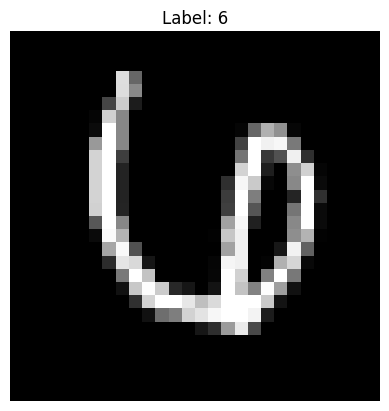

B_x shape: (784, 100)
j: 57
predict: 3


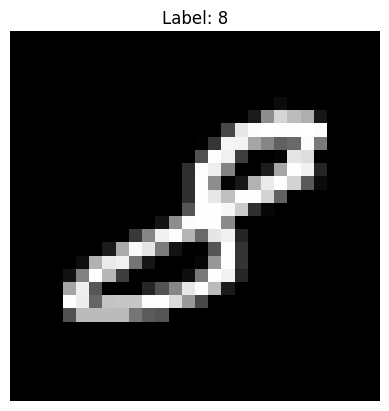

B_x shape: (784, 100)
j: 67
predict: 3


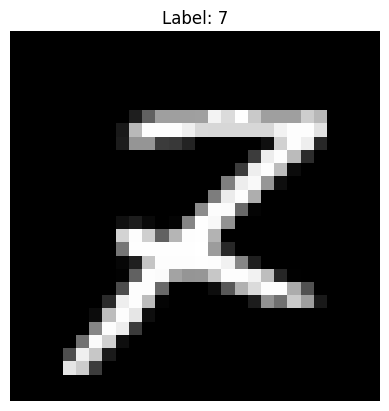

B_x shape: (784, 100)
j: 76
predict: 8


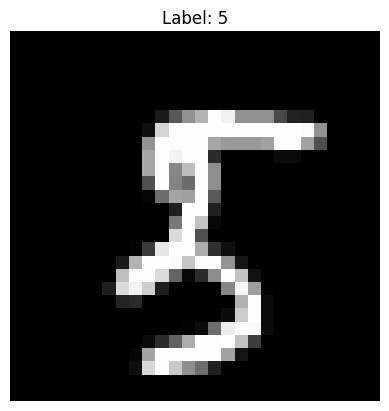

B_x shape: (784, 100)
j: 80
predict: 2


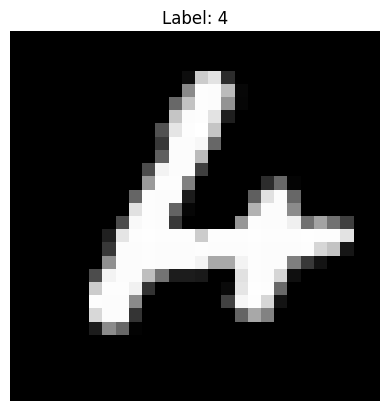

B_x shape: (784, 100)
j: 8
predict: 8


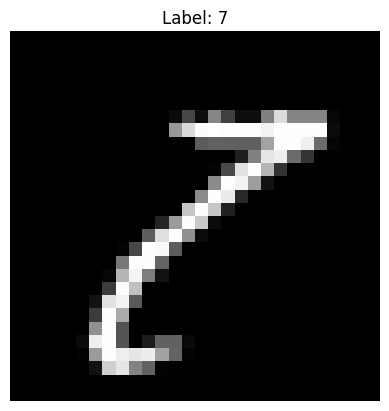

B_x shape: (784, 100)
j: 11
predict: 3


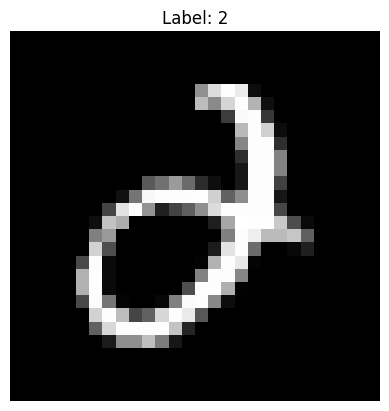

B_x shape: (784, 100)
j: 18
predict: 6


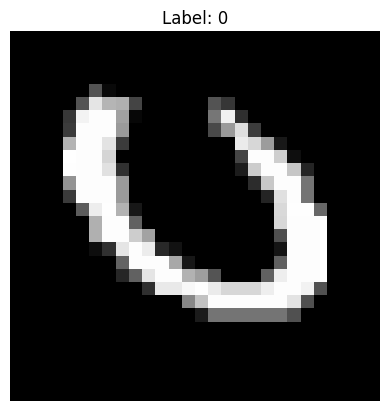

B_x shape: (784, 100)
j: 38
predict: 1


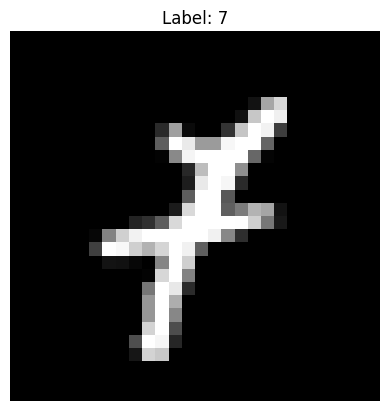

B_x shape: (784, 100)
j: 46
predict: 4


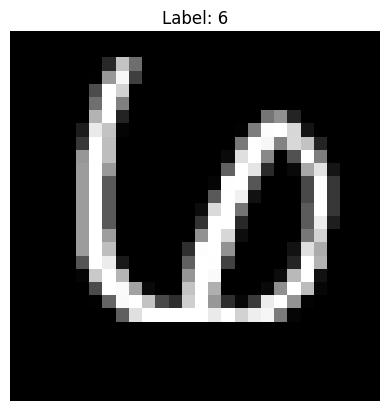

B_x shape: (784, 100)
j: 53
predict: 5


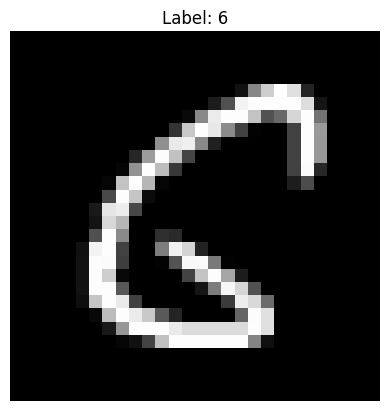

B_x shape: (784, 100)
j: 93
predict: 6


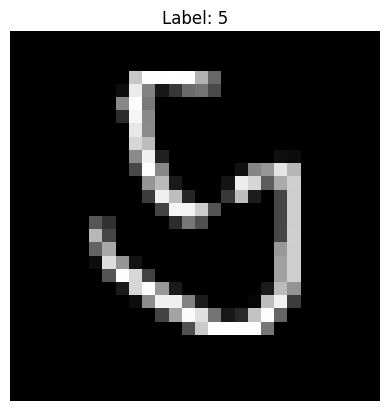

B_x shape: (784, 100)
j: 2
predict: 3


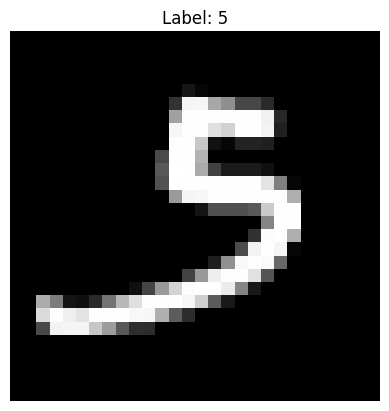

B_x shape: (784, 100)
j: 6
predict: 3


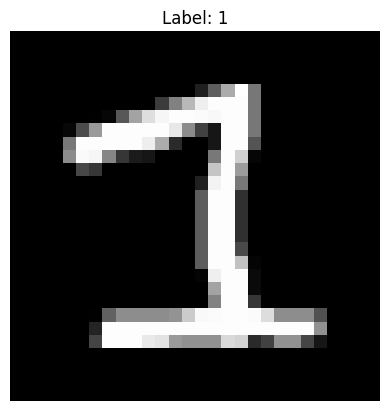

B_x shape: (784, 100)
j: 41
predict: 2


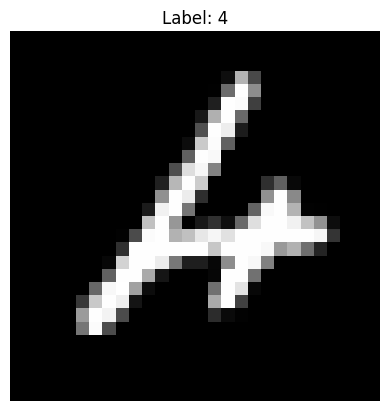

B_x shape: (784, 100)
j: 43
predict: 5


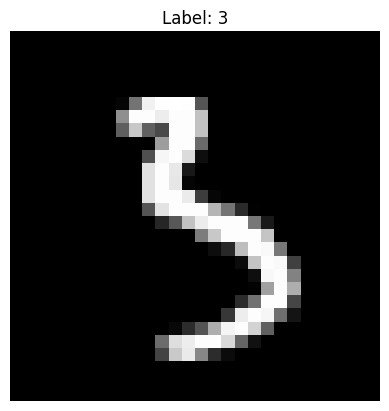

B_x shape: (784, 100)
j: 46
predict: 8


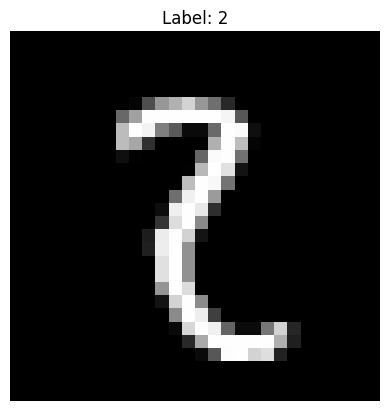

B_x shape: (784, 100)
j: 85
predict: 4


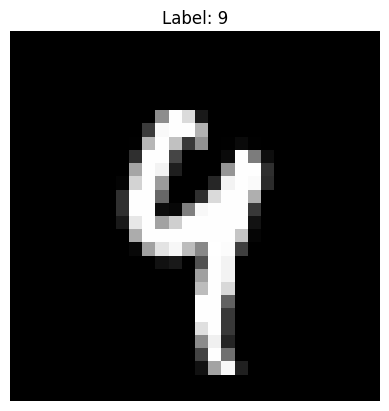

B_x shape: (784, 100)
j: 0
predict: 5


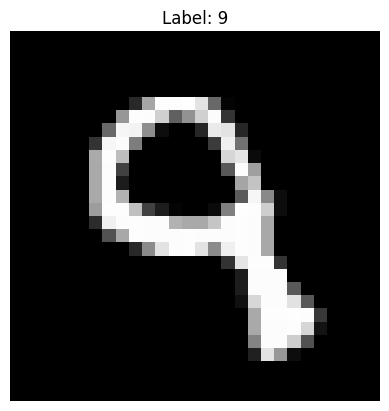

B_x shape: (784, 100)
j: 63
predict: 5


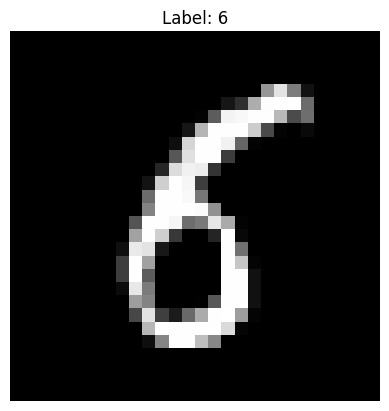

B_x shape: (784, 100)
j: 65
predict: 9


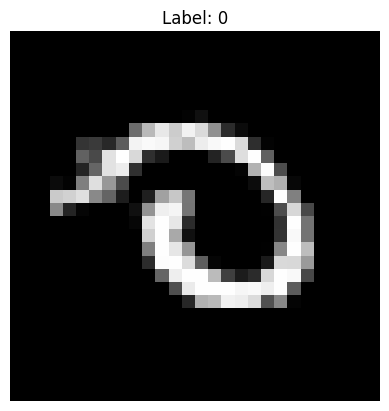

B_x shape: (784, 100)
j: 75
predict: 3


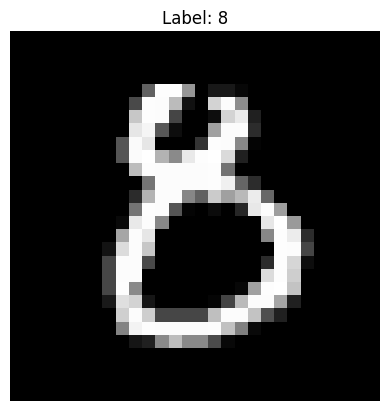

B_x shape: (784, 100)
j: 78
predict: 3


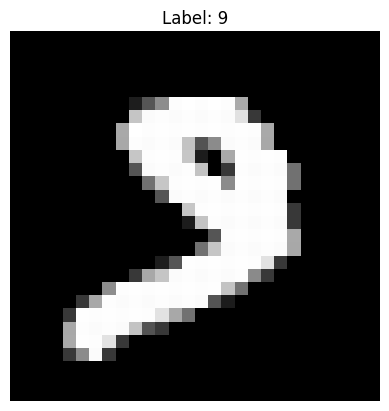

B_x shape: (784, 100)
j: 54
predict: 4


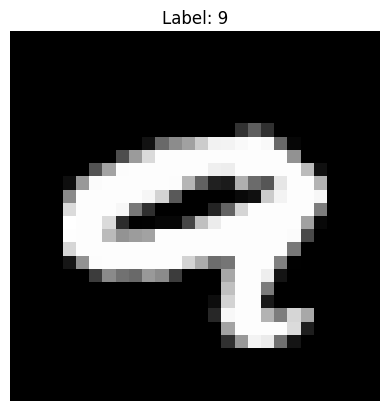

B_x shape: (784, 100)
j: 63
predict: 0


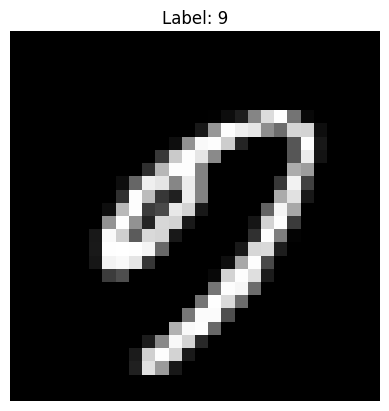

B_x shape: (784, 100)
j: 76
predict: 7


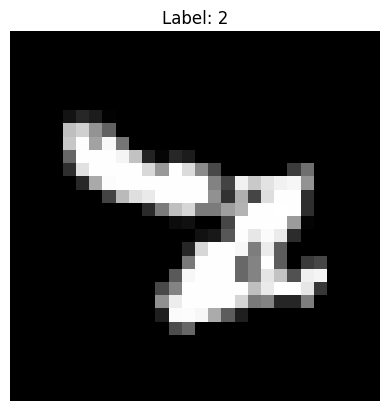

B_x shape: (784, 100)
j: 99
predict: 9


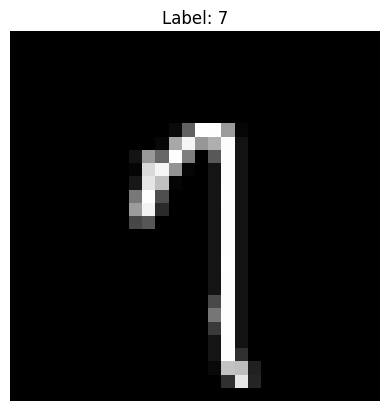

B_x shape: (784, 100)
j: 1
predict: 7


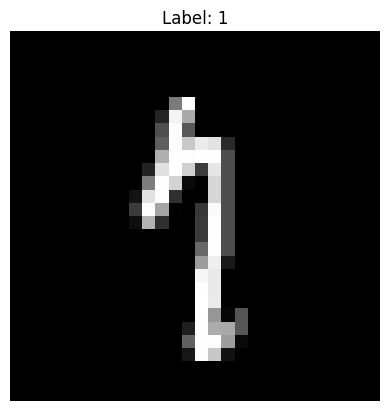

B_x shape: (784, 100)
j: 5
predict: 7


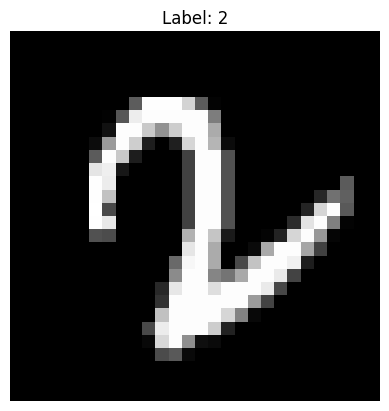

B_x shape: (784, 100)
j: 11
predict: 5


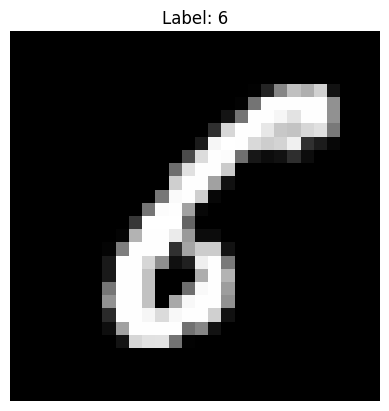

B_x shape: (784, 100)
j: 24
predict: 7


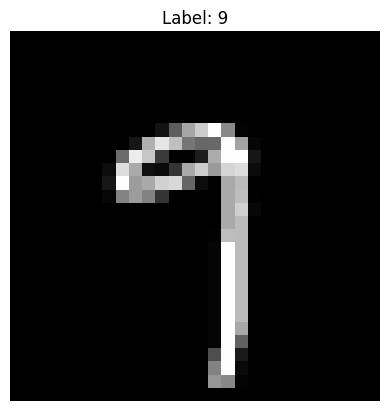

B_x shape: (784, 100)
j: 48
predict: 8


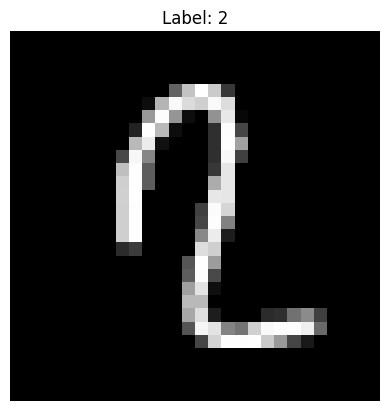

B_x shape: (784, 100)
j: 89
predict: 7


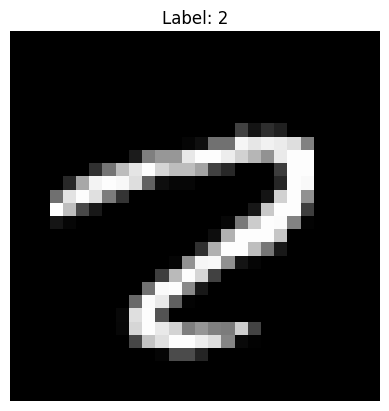

B_x shape: (784, 100)
j: 0
predict: 8


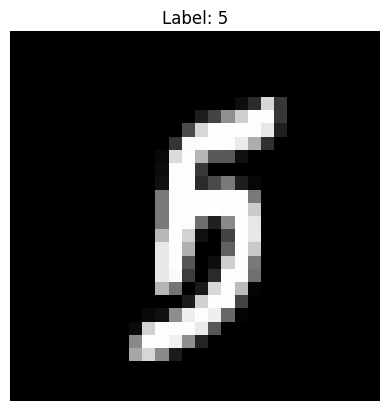

B_x shape: (784, 100)
j: 44
predict: 2


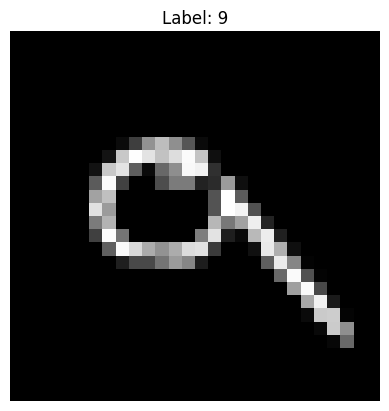

B_x shape: (784, 100)
j: 55
predict: 3


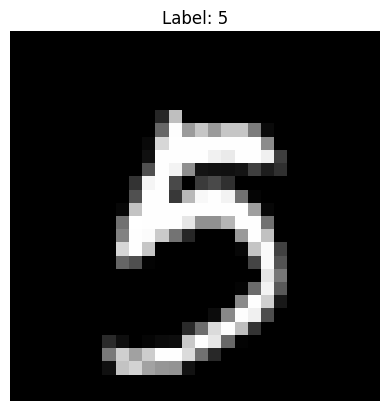

B_x shape: (784, 100)
j: 69
predict: 4


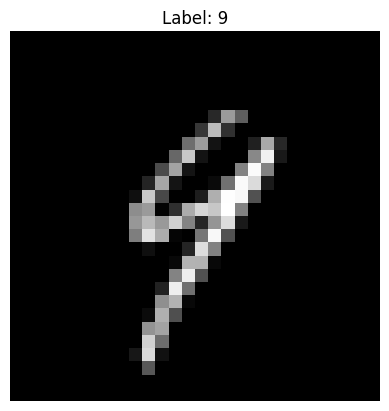

B_x shape: (784, 100)
j: 74
predict: 6


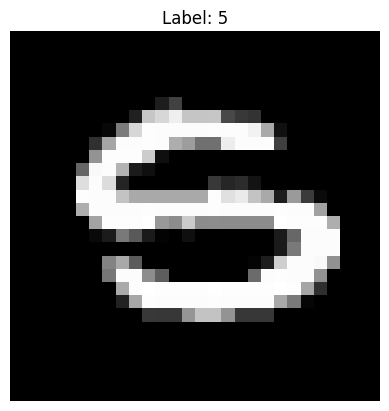

B_x shape: (784, 100)
j: 97
predict: 7


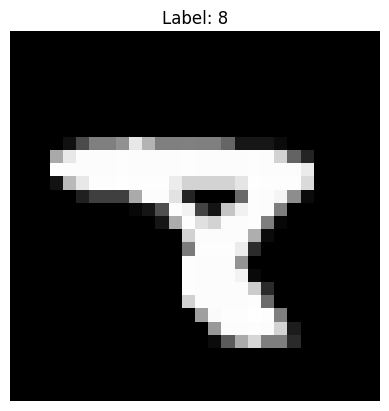

B_x shape: (784, 100)
j: 98
predict: 3


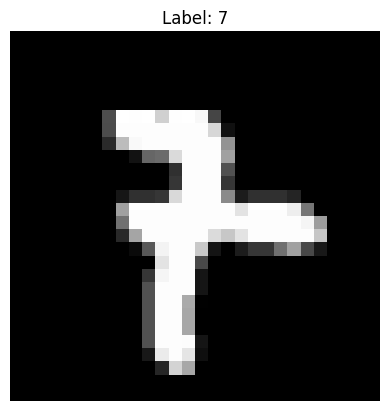

B_x shape: (784, 100)
j: 36
predict: 5


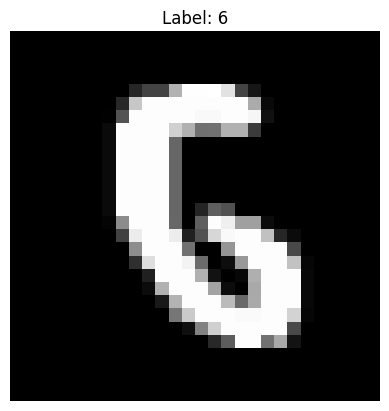

B_x shape: (784, 100)
j: 47
predict: 4


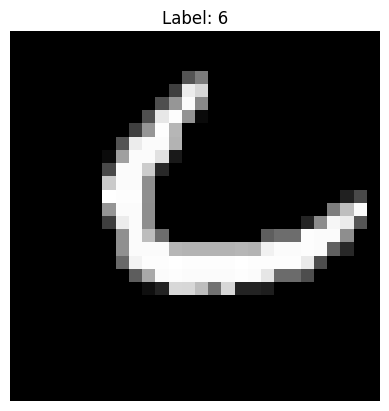

B_x shape: (784, 100)
j: 75
predict: 9


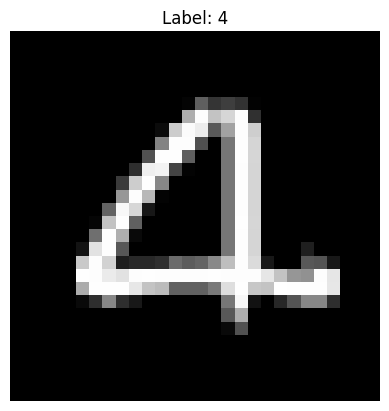

B_x shape: (784, 100)
j: 1
predict: 4


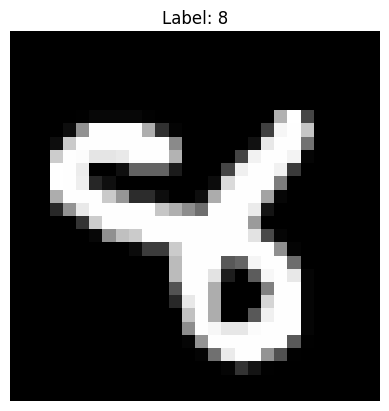

B_x shape: (784, 100)
j: 15
predict: 4


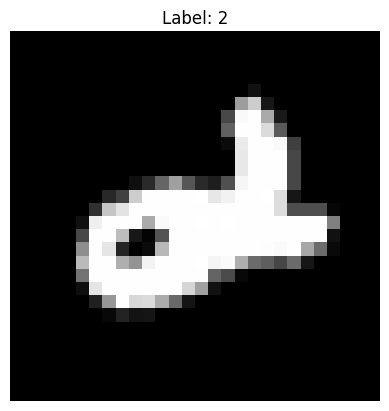

B_x shape: (784, 100)
j: 35
predict: 5


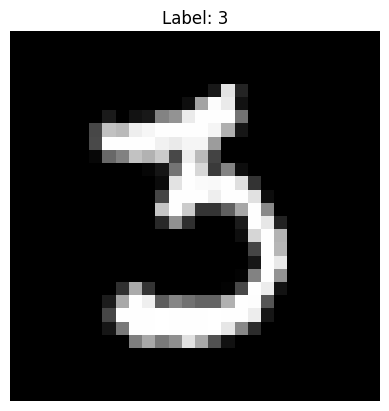

B_x shape: (784, 100)
j: 39
predict: 9


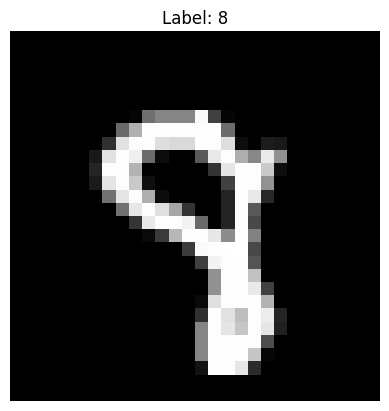

B_x shape: (784, 100)
j: 31
predict: 7


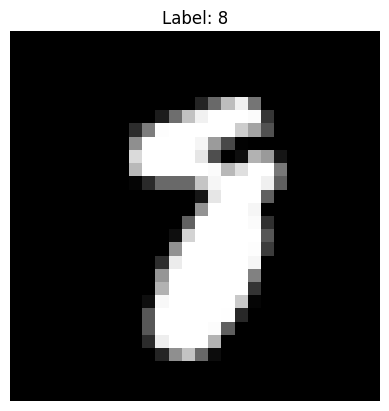

B_x shape: (784, 100)
j: 40
predict: 5


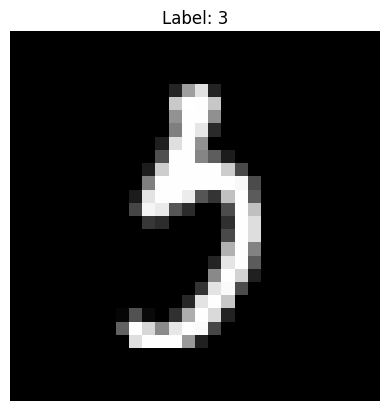

B_x shape: (784, 100)
j: 7
predict: 3


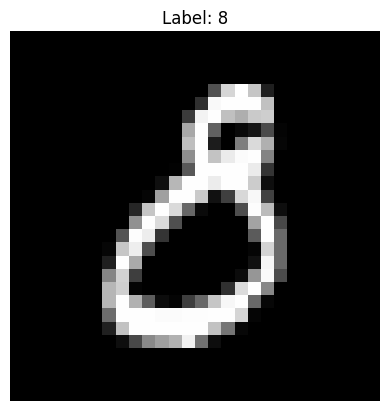

B_x shape: (784, 100)
j: 14
predict: 4


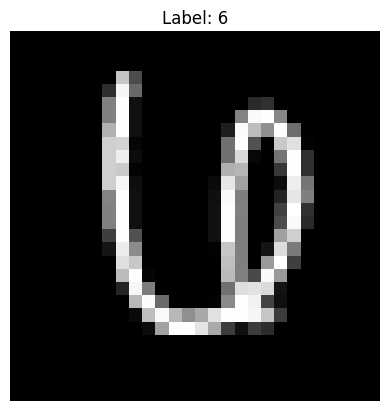

B_x shape: (784, 100)
j: 23
predict: 4


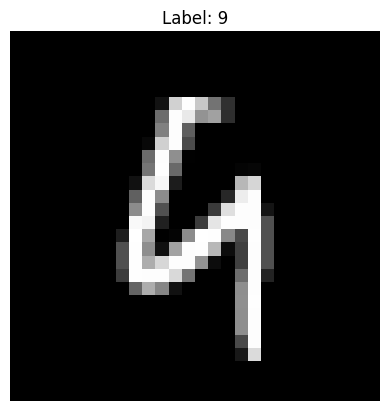

B_x shape: (784, 100)
j: 60
predict: 9


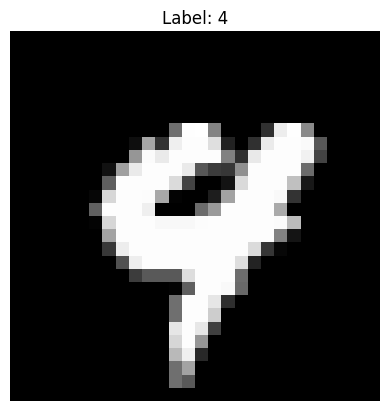

B_x shape: (784, 100)
j: 74
predict: 0


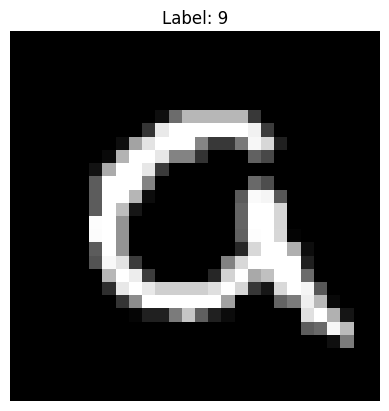

B_x shape: (784, 100)
j: 76
predict: 4


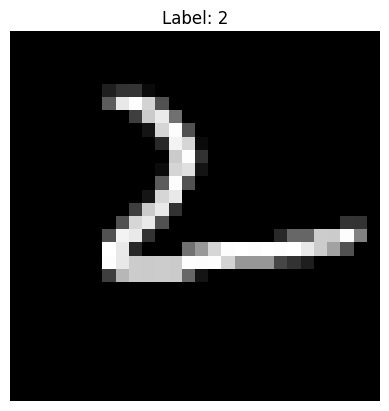

B_x shape: (784, 100)
j: 79
predict: 6


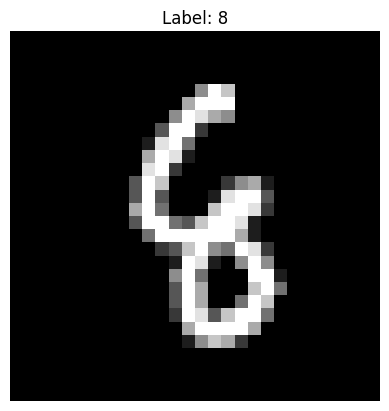

B_x shape: (784, 100)
j: 80
predict: 8


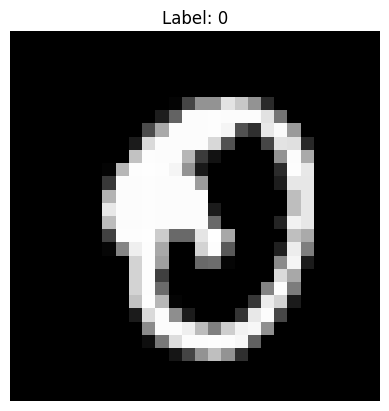

B_x shape: (784, 100)
j: 86
predict: 1


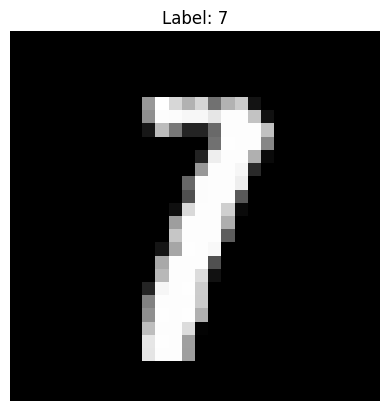

B_x shape: (784, 100)
j: 18
predict: 4


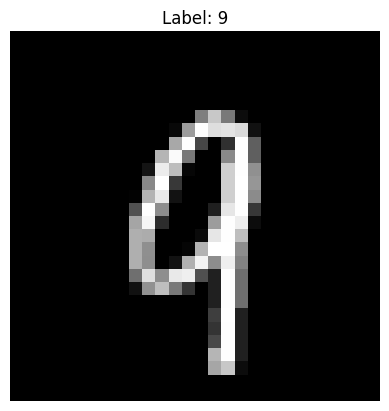

B_x shape: (784, 100)
j: 56
predict: 4


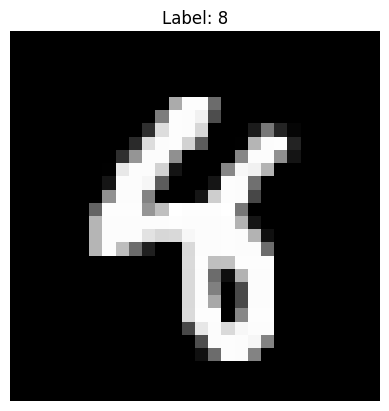

B_x shape: (784, 100)
j: 66
predict: 3


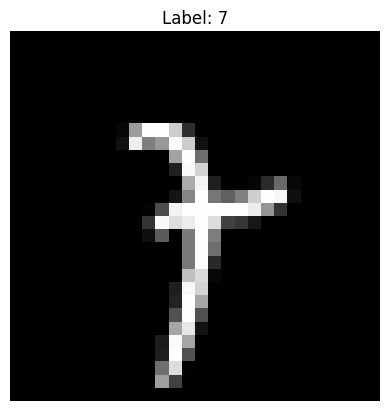

B_x shape: (784, 100)
j: 90
predict: 8


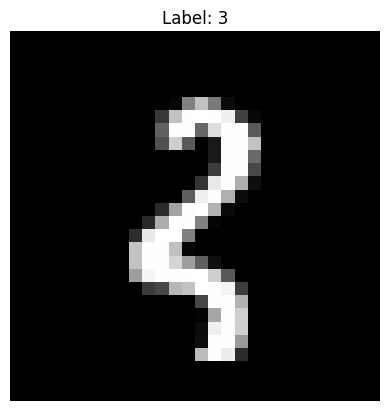

B_x shape: (784, 100)
j: 31
predict: 6


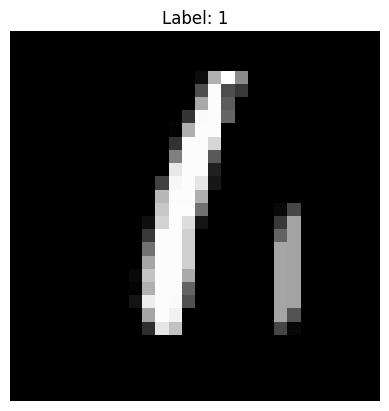

B_x shape: (784, 100)
j: 0
predict: 9


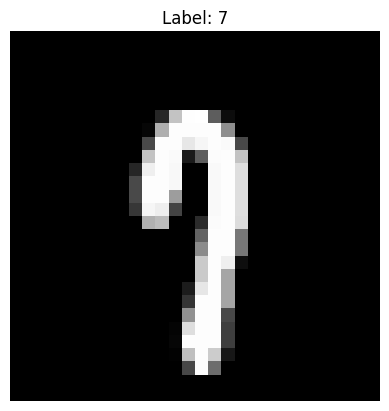

B_x shape: (784, 100)
j: 42
predict: 8


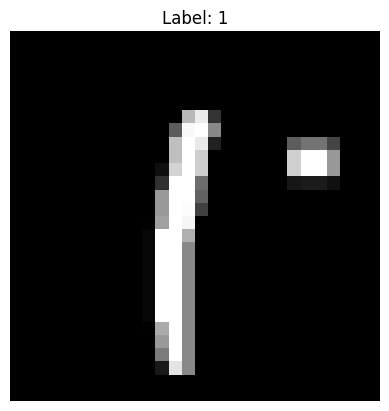

B_x shape: (784, 100)
j: 53
predict: 6


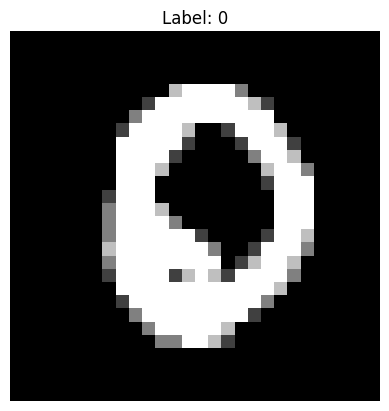

B_x shape: (784, 100)
j: 34
predict: 2


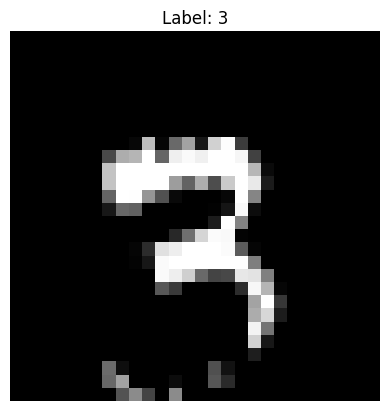

B_x shape: (784, 100)
j: 58
predict: 4


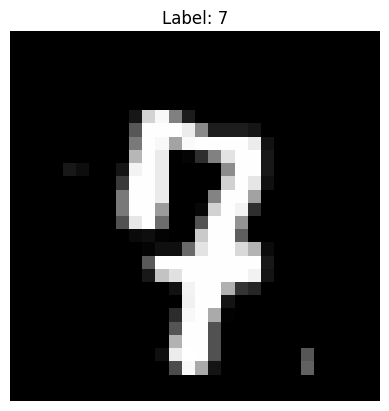

B_x shape: (784, 100)
j: 88
predict: 0


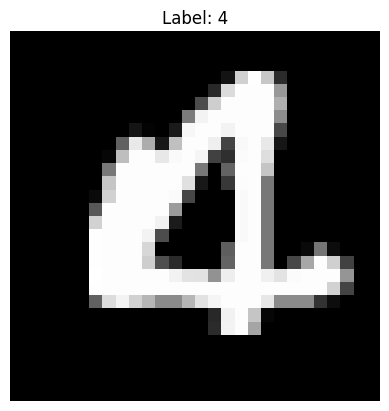

B_x shape: (784, 100)
j: 13
predict: 1


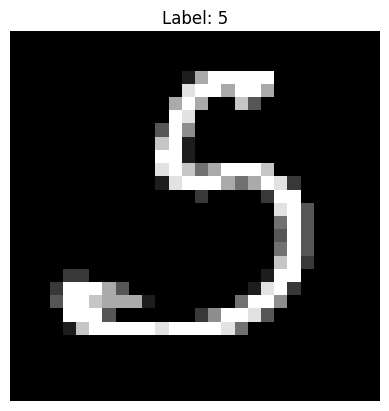

B_x shape: (784, 100)
j: 36
predict: 9


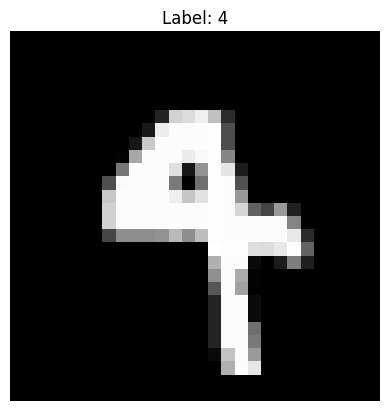

B_x shape: (784, 100)
j: 37
predict: 3


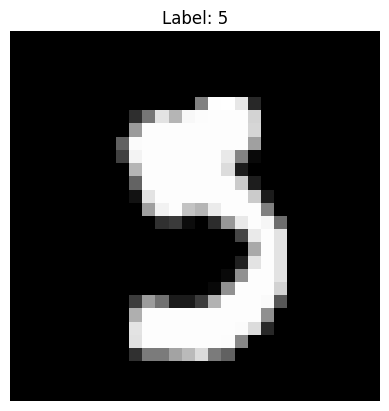

B_x shape: (784, 100)
j: 55
predict: 8


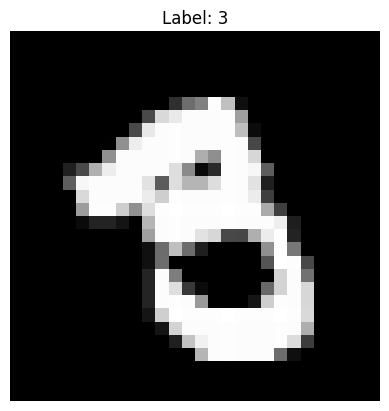

B_x shape: (784, 100)
j: 72
predict: 3


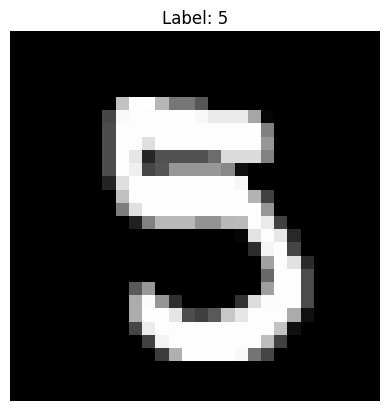

B_x shape: (784, 100)
j: 73
predict: 8


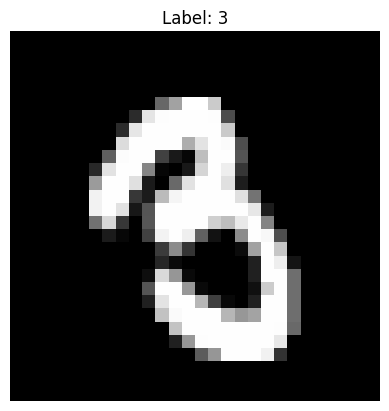

B_x shape: (784, 100)
j: 35
predict: 0


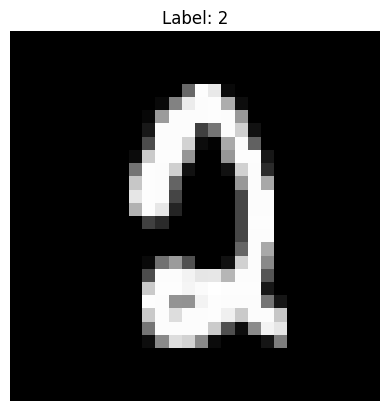

B_x shape: (784, 100)
j: 45
predict: 9


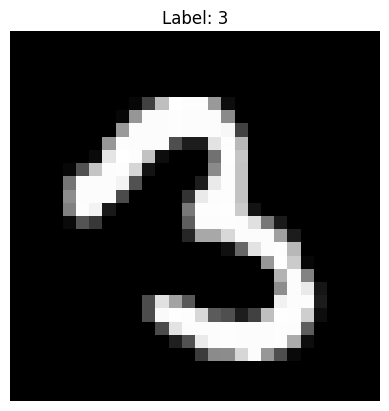

B_x shape: (784, 100)
j: 46
predict: 8


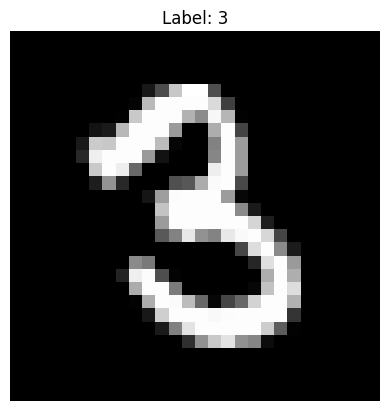

B_x shape: (784, 100)
j: 59
predict: 9


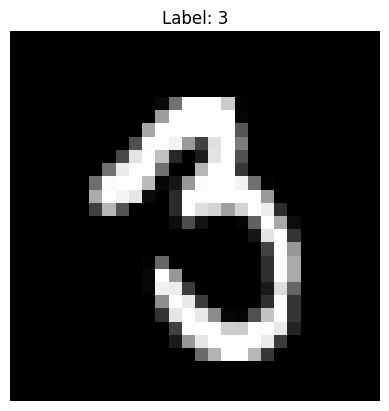

B_x shape: (784, 100)
j: 65
predict: 8


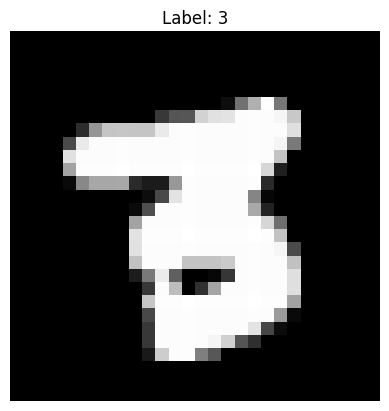

B_x shape: (784, 100)
j: 71
predict: 3


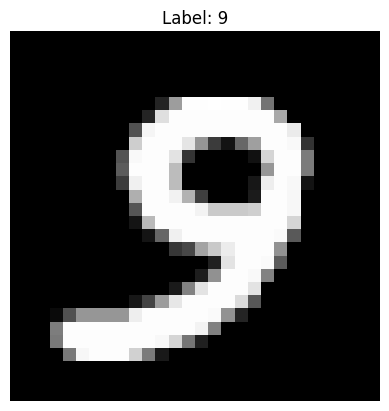

B_x shape: (784, 100)
j: 91
predict: 3


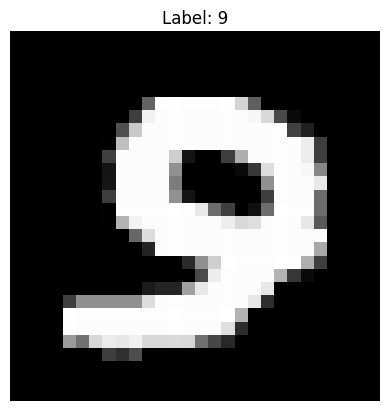

B_x shape: (784, 100)
j: 57
predict: 0


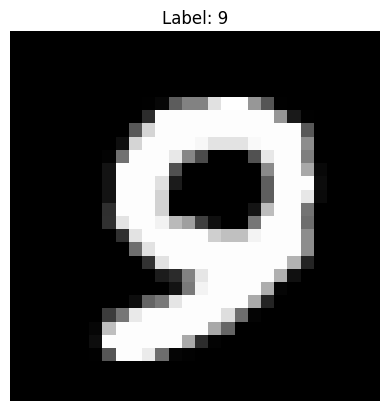

B_x shape: (784, 100)
j: 72
predict: 0


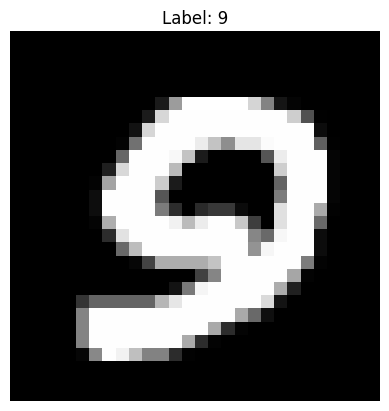

B_x shape: (784, 100)
j: 73
predict: 4


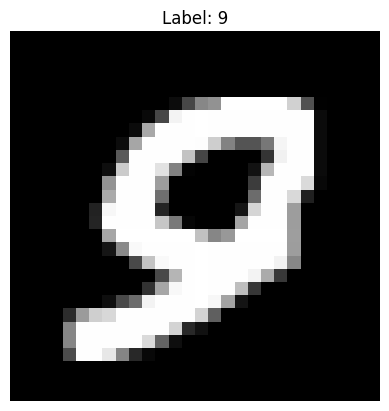

B_x shape: (784, 100)
j: 5
predict: 0


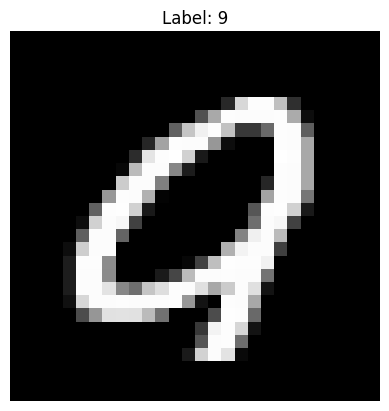

B_x shape: (784, 100)
j: 55
predict: 9


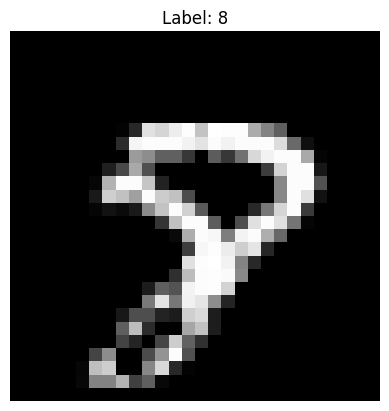

B_x shape: (784, 100)
j: 60
predict: 3


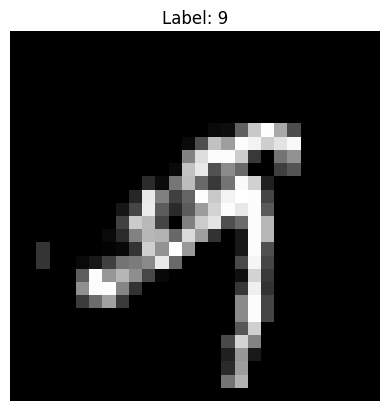

B_x shape: (784, 100)
j: 74
predict: 6


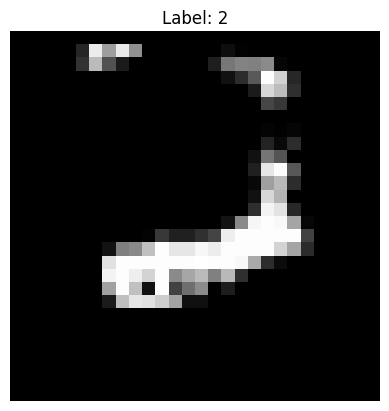

B_x shape: (784, 100)
j: 97
predict: 7


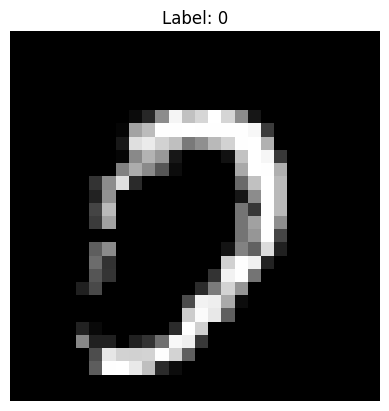

B_x shape: (784, 100)
j: 98
predict: 3


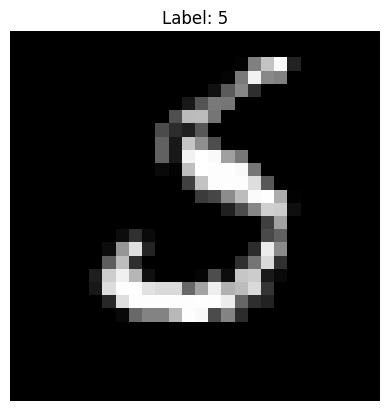

B_x shape: (784, 100)
j: 8
predict: 5


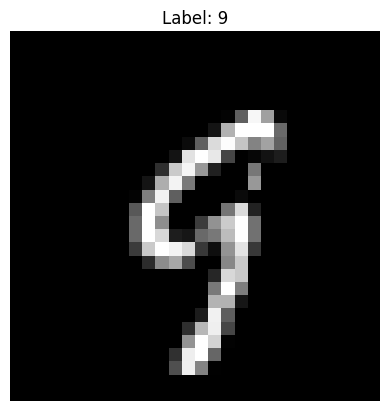

B_x shape: (784, 100)
j: 25
predict: 4


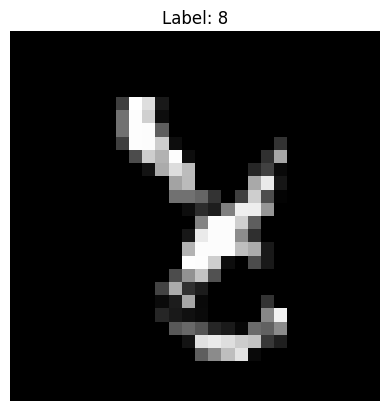

B_x shape: (784, 100)
j: 51
predict: 5


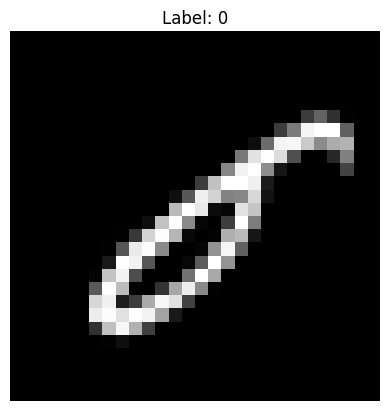

B_x shape: (784, 100)
j: 6
predict: 3


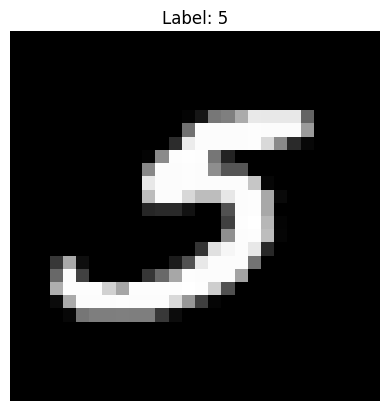

B_x shape: (784, 100)
j: 65
predict: 6


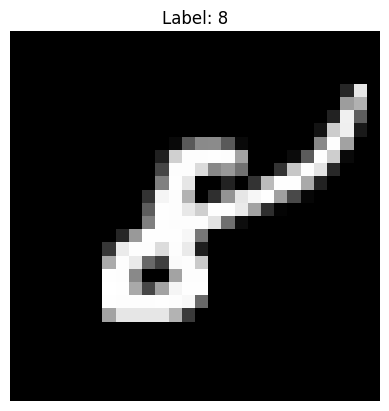

B_x shape: (784, 100)
j: 83
predict: 6


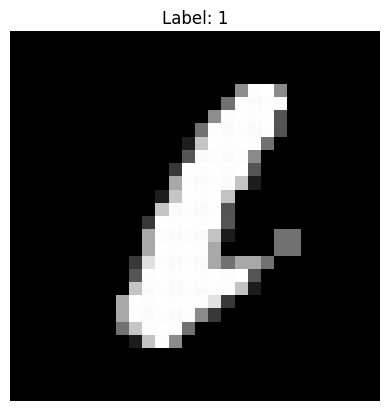

B_x shape: (784, 100)
j: 47
predict: 4


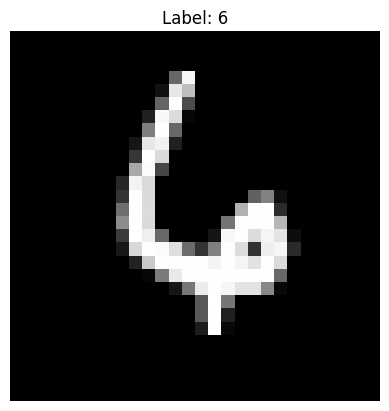

B_x shape: (784, 100)
j: 45
predict: 9


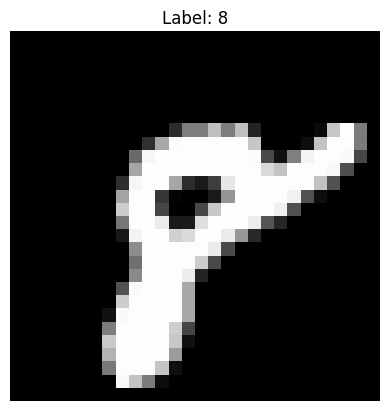

B_x shape: (784, 100)
j: 54
predict: 7


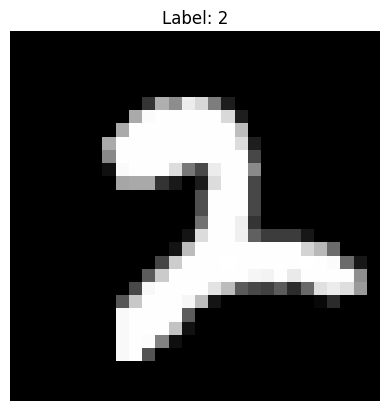

B_x shape: (784, 100)
j: 16
predict: 6


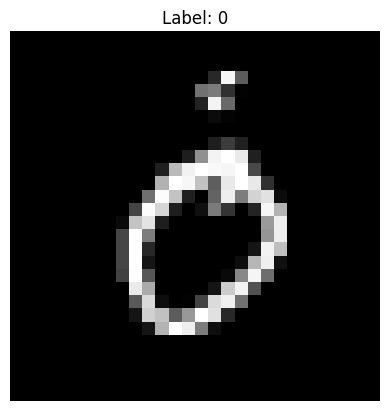

B_x shape: (784, 100)
j: 32
predict: 1


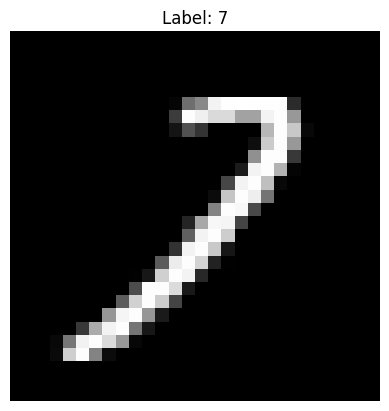

B_x shape: (784, 100)
j: 34
predict: 8


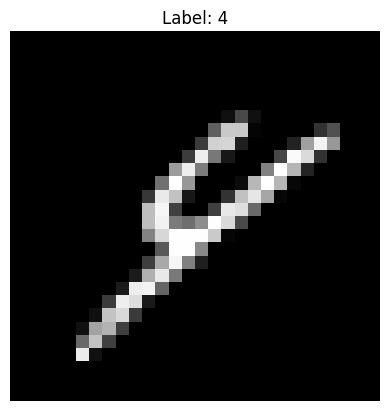

B_x shape: (784, 100)
j: 51
predict: 6


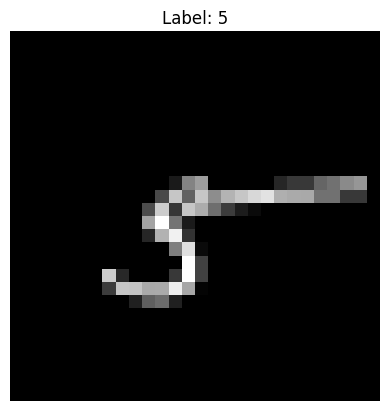

B_x shape: (784, 100)
j: 59
predict: 5


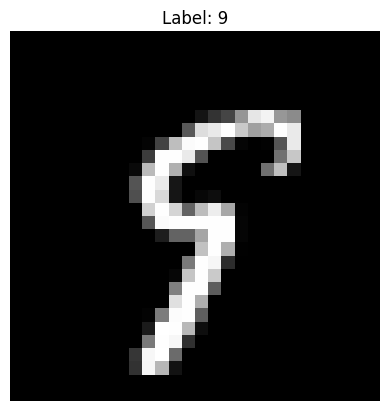

B_x shape: (784, 100)
j: 97
predict: 6


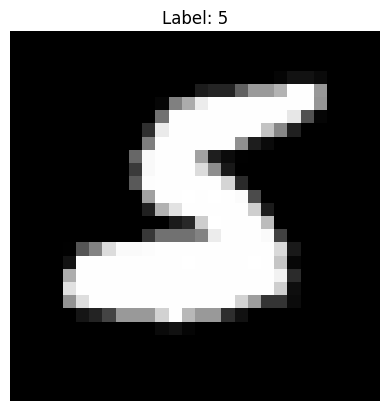

B_x shape: (784, 100)
j: 49
predict: 2


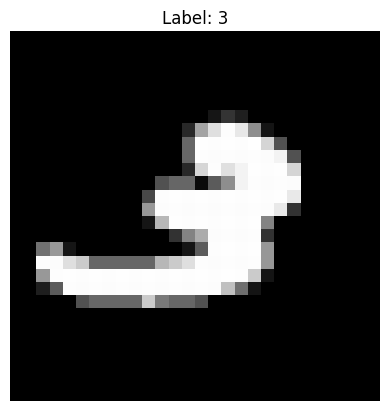

B_x shape: (784, 100)
j: 58
predict: 2


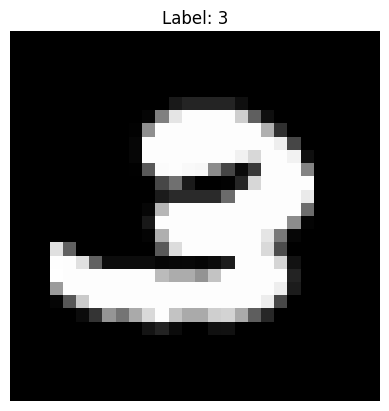

B_x shape: (784, 100)
j: 21
predict: 6


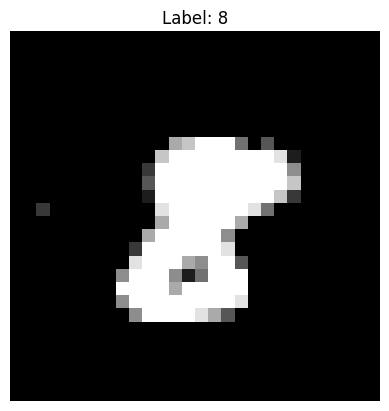

B_x shape: (784, 100)
j: 62
predict: 8


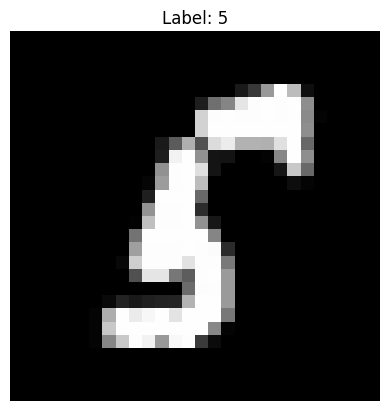

B_x shape: (784, 100)
j: 94
predict: 8


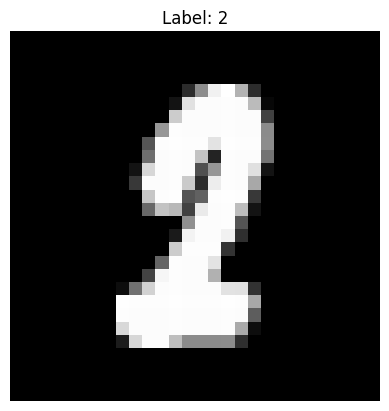

B_x shape: (784, 100)
j: 12
predict: 8


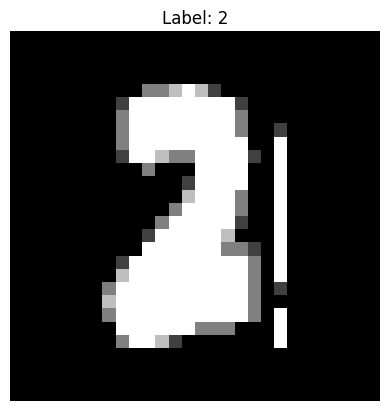

B_x shape: (784, 100)
j: 77
predict: 9


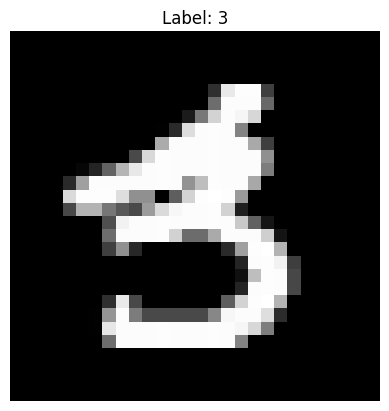

B_x shape: (784, 100)
j: 11
predict: 4


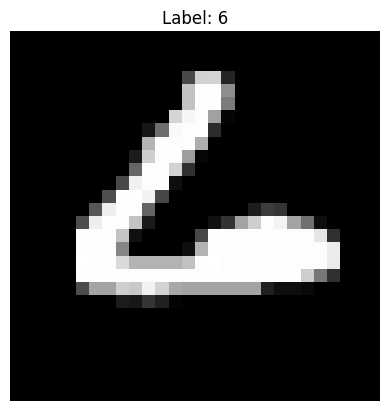

B_x shape: (784, 100)
j: 8
predict: 6


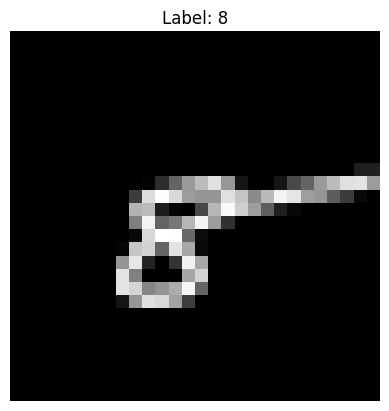

B_x shape: (784, 100)
j: 20
predict: 9


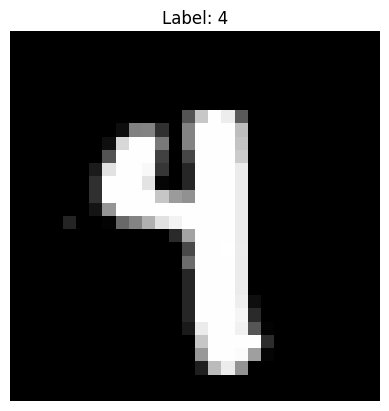

B_x shape: (784, 100)
j: 9
predict: 2


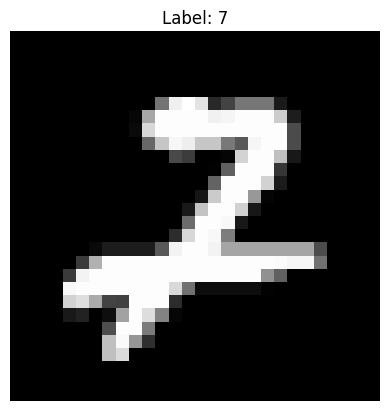

B_x shape: (784, 100)
j: 15
predict: 2


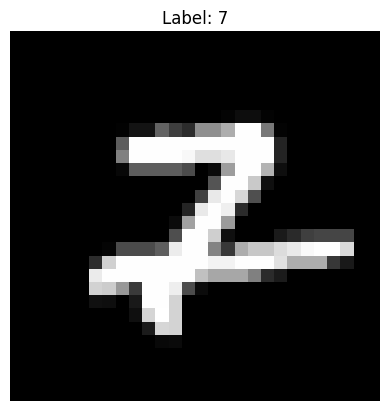

B_x shape: (784, 100)
j: 19
predict: 2


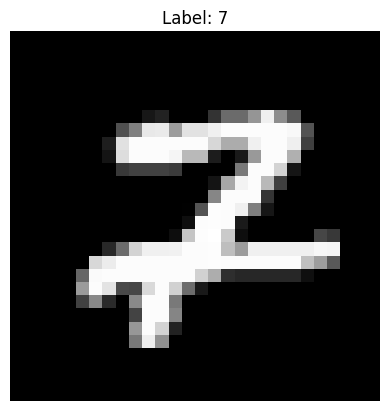

B_x shape: (784, 100)
j: 24
predict: 2


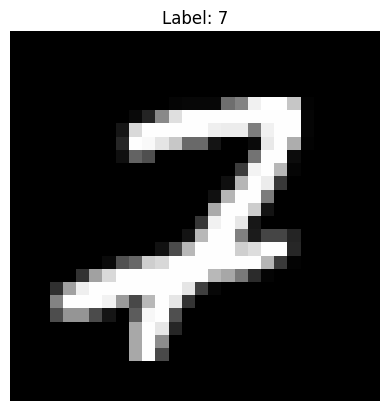

B_x shape: (784, 100)
j: 80
predict: 5


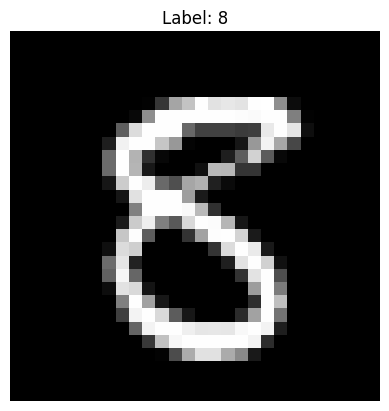

B_x shape: (784, 100)
j: 16
predict: 5


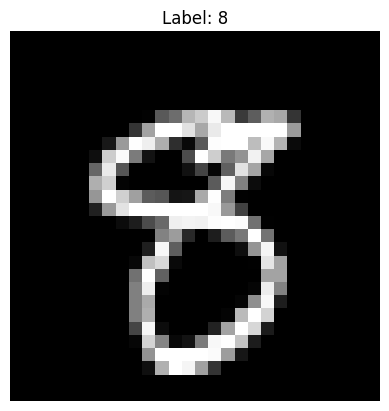

B_x shape: (784, 100)
j: 94
predict: 5


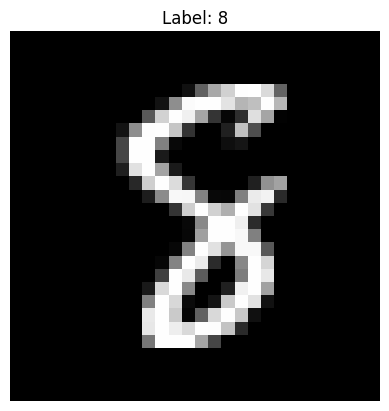

B_x shape: (784, 100)
j: 27
predict: 3


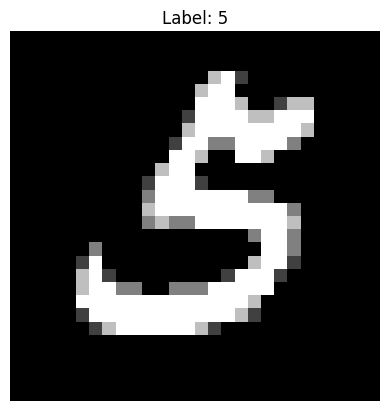

B_x shape: (784, 100)
j: 82
predict: 3


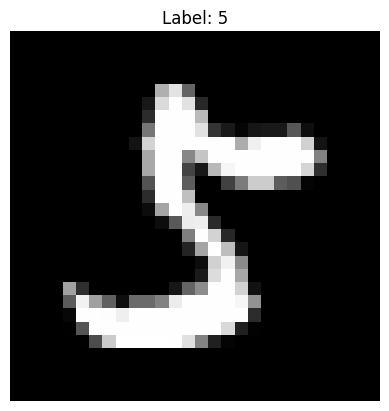

B_x shape: (784, 100)
j: 87
predict: 4


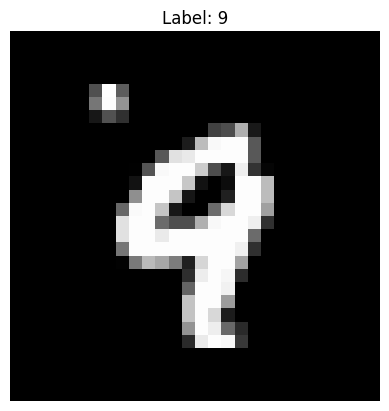

B_x shape: (784, 100)
j: 24
predict: 8


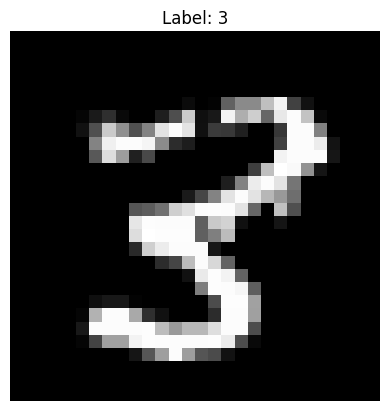

B_x shape: (784, 100)
j: 34
predict: 3


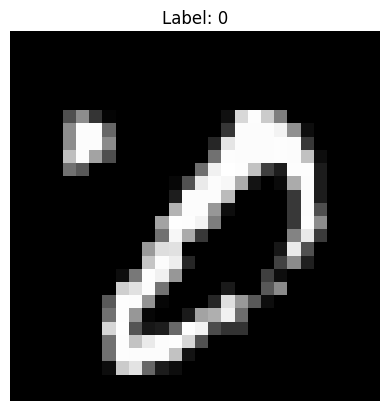

B_x shape: (784, 100)
j: 42
predict: 7


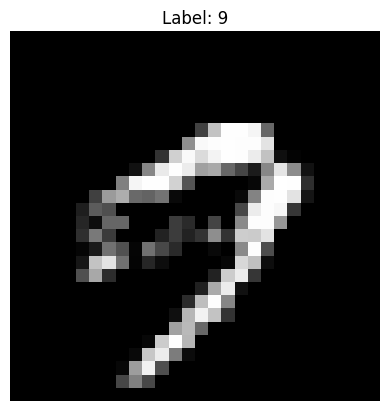

B_x shape: (784, 100)
j: 79
predict: 5


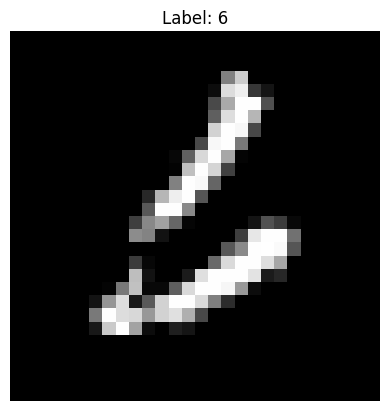

B_x shape: (784, 100)
j: 92
predict: 7


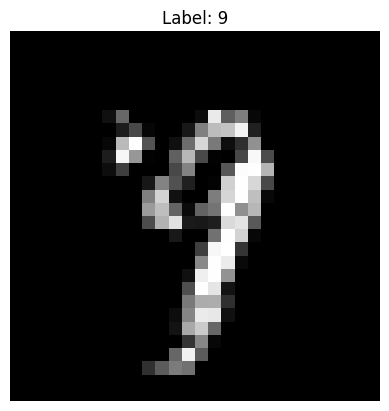

B_x shape: (784, 100)
j: 26
predict: 3


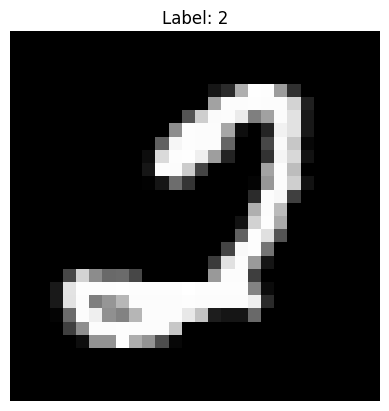

B_x shape: (784, 100)
j: 29
predict: 6


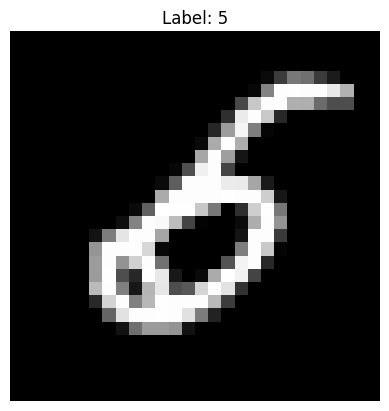

B_x shape: (784, 100)
j: 33
predict: 8


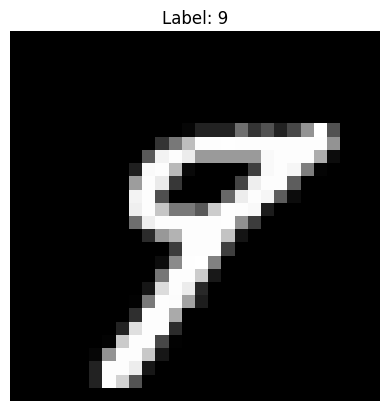

B_x shape: (784, 100)
j: 45
predict: 0


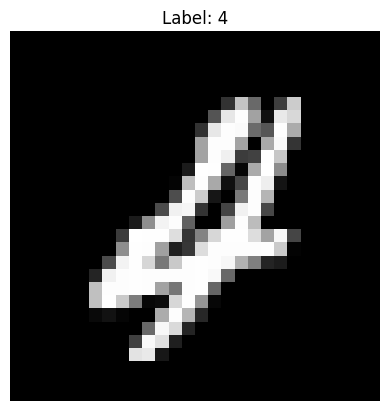

B_x shape: (784, 100)
j: 68
predict: 0


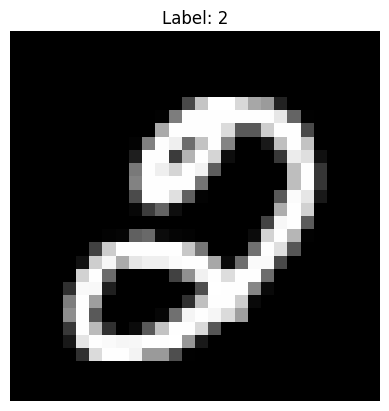

B_x shape: (784, 100)
j: 70
predict: 0


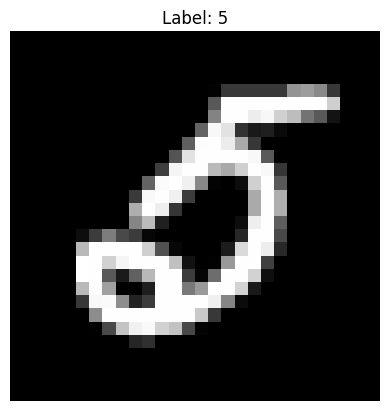

B_x shape: (784, 100)
j: 79
predict: 0


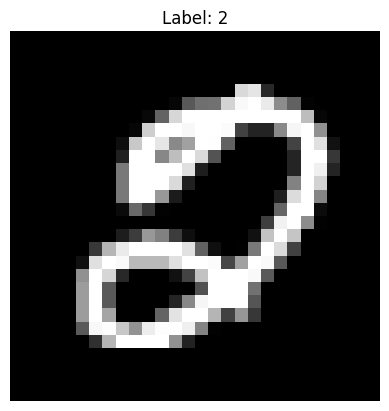

B_x shape: (784, 100)
j: 92
predict: 9


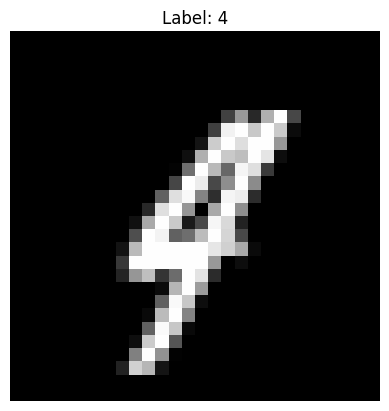

B_x shape: (784, 100)
j: 8
predict: 4


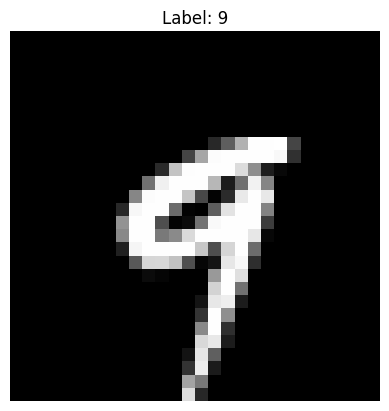

B_x shape: (784, 100)
j: 39
predict: 3


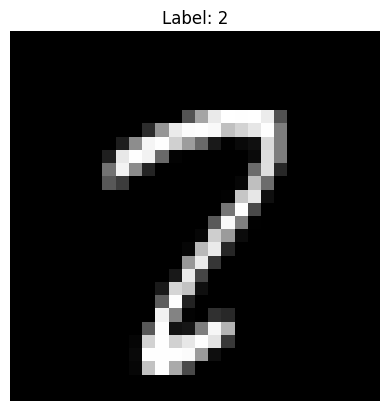

B_x shape: (784, 100)
j: 58
predict: 8


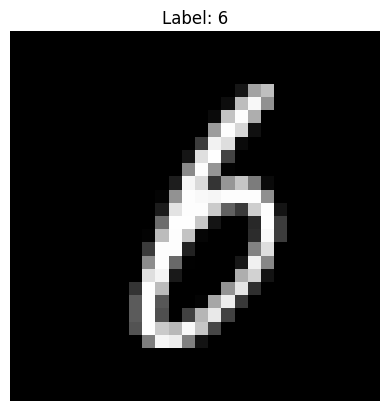

B_x shape: (784, 100)
j: 44
predict: 9


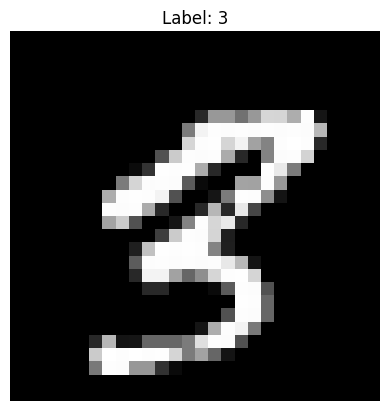

accuracy:  97.21


In [16]:
model = MLP(0.01,x_train,y_etrain,x_test,y_etest,100)
model.training()
model.evaluate()

In [78]:
model.evaluate()

/tmp/ipykernel_3751/1520288622.py:34: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-x))


accuracy:  91.61
